In [1]:
# Week 7 - Section 1: Verify the saved Week 6 baseline

from hashlib import sha256
import json
from pathlib import Path

import numpy as np
import pandas as pd

W7_ROOT = Path.home() / "PycharmProjects" / "FYP_Salary_Prediction"
W6_RUN = W7_ROOT / "results" / "week6" / "extended_nested_cv" / "v1"


def read_w6_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


w6_config = read_w6_json(W6_RUN / "experiment_config.json")
w6_protocol = w6_config["protocol"]
w6_summary = read_w6_json(W6_RUN / "nested_cv_summary" / "section5_summary.json")

assert w6_summary["Status"] == "Passed"
assert w6_summary["Test Set Used"] is False
assert w6_protocol["outer_folds"] == 5

w6_oof = pd.read_csv(W6_RUN / "nested_cv_summary" / "oof_predictions.csv")
assert len(w6_oof) == 21_940
assert w6_oof["source_row_id"].notna().all() and w6_oof["source_row_id"].is_unique
assert set(w6_oof["Outer Fold"]) == set(range(1, 6))

prediction_columns = ["source_row_id", "Outer Fold", "Actual G8", "Predicted G8"]
w6_catboost_params = {}
fold_predictions = []

for fold in range(1, 6):
    fold_dir = W6_RUN / "nested_cv" / f"outer_fold_{fold:02d}"
    record = read_w6_json(fold_dir / "fold_complete.json")
    assert record["Outer Fold"] == fold
    assert (record["Selected Model"], record["Selected Target"]) == ("CatBoost", "ln(G8)")

    pred = pd.read_csv(fold_dir / "outer_validation_predictions.csv")
    assert len(pred) == record["Outer Validation Rows"] == 4_388
    assert pred["Outer Fold"].eq(fold).all()
    ordered_ids = ",".join(map(str, pred["source_row_id"]))
    assert sha256(ordered_ids.encode("utf-8")).hexdigest() == record["Outer Validation Index SHA256"]
    fold_predictions.append(pred[prediction_columns])

    candidates = pd.read_csv(fold_dir / "candidate_summary.csv")
    w6_catboost_params[fold] = {}
    for target in ("Original G8", "ln(G8)"):
        row = candidates.loc[
            candidates["Model"].eq("CatBoost") & candidates["Target"].eq(target)
        ]
        assert len(row) == 1, f"Fold {fold}: missing or repeated CatBoost parameter record"
        w6_catboost_params[fold][target] = json.loads(row["Best Params"].iloc[0])

combined = pd.concat(fold_predictions, ignore_index=True)
pd.testing.assert_frame_equal(
    combined.sort_values("source_row_id").reset_index(drop=True),
    w6_oof[prediction_columns].sort_values("source_row_id").reset_index(drop=True),
)

w6_oof["Prediction Error"] = w6_oof["Predicted G8"] - w6_oof["Actual G8"]
error = w6_oof["Prediction Error"]
assert np.isfinite(error).all()

print("Verified outer folds:", sorted(w6_catboost_params))
print(f"Verified development OOF rows: {len(w6_oof):,}")
print(f"Week 6 pooled MAE: RM {error.abs().mean():,.2f}")
print(f"Week 6 mean prediction error: RM {error.mean():,.2f}")
print("Section 1 passed.")

Verified outer folds: [1, 2, 3, 4, 5]
Verified development OOF rows: 21,940
Week 6 pooled MAE: RM 749.66
Week 6 mean prediction error: RM -197.23
Section 1 passed.


In [2]:
# Week 7 - Section 2: Audit identical records within the development set

from sklearn.model_selection import KFold, train_test_split

raw_path = W7_ROOT / "data" / w6_protocol["data_file"]
with raw_path.open("rb") as raw_file:
    assert sha256(raw_file.read()).hexdigest() == w6_config["data_sha256"], (
        "The raw CSV differs from the Week 6 input."
    )

# Reproduce the original development split using row numbers only.
w7_dev_ids = train_test_split(
    np.arange(27_425),
    test_size=w6_protocol["test_size"],
    random_state=w6_protocol["split_seed"],
    shuffle=True,
)[0]
dev_id_set = set(w7_dev_ids)
assert dev_id_set == set(w6_oof["source_row_id"])

# Skip non-development data rows. The CSV header is line 0.
w7_dev_raw = pd.read_csv(
    raw_path,
    skiprows=lambda line: line > 0 and (line - 1) not in dev_id_set,
)
assert len(w7_dev_raw) == len(w7_dev_ids)
w7_dev_raw.index = pd.Index(sorted(dev_id_set), name="source_row_id")
w7_dev_raw = w7_dev_raw.loc[w7_dev_ids].copy()

oof_by_id = w6_oof.set_index("source_row_id")
np.testing.assert_allclose(
    w7_dev_raw[w6_protocol["target"]].to_numpy(),
    oof_by_id.loc[w7_dev_ids, "Actual G8"].to_numpy(),
    rtol=0,
    atol=1e-9,
)

# Verify fold membership and row order against Week 6.
w7_cv = KFold(
    n_splits=w6_protocol["outer_folds"],
    shuffle=True,
    random_state=w6_protocol["outer_seed"],
)
w7_outer_splits = {}

for fold, (train_pos, val_pos) in enumerate(w7_cv.split(w7_dev_raw), start=1):
    train_ids = w7_dev_ids[train_pos]
    val_ids = w7_dev_ids[val_pos]
    fold_dir = W6_RUN / "nested_cv" / f"outer_fold_{fold:02d}"
    record = read_w6_json(fold_dir / "fold_complete.json")

    for label, ids in (("Train", train_ids), ("Validation", val_ids)):
        payload = ",".join(map(str, ids)).encode("utf-8")
        assert sha256(payload).hexdigest() == record[f"Outer {label} Index SHA256"], (
            f"Fold {fold}: {label.lower()} row order differs from Week 6."
        )

    w7_outer_splits[fold] = (train_ids, val_ids)

# Group records by all raw columns, excluding the row index.
row_groups = w7_dev_raw.groupby(
    list(w7_dev_raw.columns), dropna=False, sort=False
).ngroup()

w7_duplicate_oof = oof_by_id.loc[
    w7_dev_ids, ["Outer Fold", "Prediction Error"]
].copy()
w7_duplicate_oof["Exact match in fold training"] = False

for train_ids, val_ids in w7_outer_splits.values():
    w7_duplicate_oof.loc[val_ids, "Exact match in fold training"] = (
        row_groups.loc[val_ids].isin(row_groups.loc[train_ids]).to_numpy()
    )

group_sizes = row_groups.value_counts()
match = w7_duplicate_oof["Exact match in fold training"]
errors = w7_duplicate_oof["Prediction Error"]

w7_duplicate_summary = pd.DataFrame([
    {
        "OOF subset": label,
        "Rows": len(e),
        "MAE (RM)": e.abs().mean(),
        "RMSE (RM)": np.sqrt(e.pow(2).mean()),
        "Mean error (RM)": e.mean(),
    }
    for label, e in [
        ("All development rows", errors),
        ("No exact match in fold training", errors[~match]),
    ]
])

print("Verified Week 6 row order in all five folds.")
print("Development groups with identical rows:", int(group_sizes.gt(1).sum()))
print("Extra identical development rows:", int(len(row_groups) - len(group_sizes)))
print("OOF rows with an exact match in their training fold:", int(match.sum()))
print(w7_duplicate_summary.round(2).to_string(index=False))
print("Section 2 passed.")

Verified Week 6 row order in all five folds.
Development groups with identical rows: 136
Extra identical development rows: 150
OOF rows with an exact match in their training fold: 237
                     OOF subset  Rows  MAE (RM)  RMSE (RM)  Mean error (RM)
           All development rows 21940    749.66    1579.51          -197.23
No exact match in fold training 21703    754.09    1586.64          -199.40
Section 2 passed.


In [3]:
# Week 7 - Section 3: CatBoost retransformation pilot (outer Fold 1)

from catboost import CatBoostRegressor

w7_cat_features = [
    "State", "Strata", "Sex", "Ethnic_Group", "Marital_Status",
    "Occupation_Group", "Industry_Section",
]

occupation_groups = dict(enumerate([
    "Armed Forces", "Managers", "Professionals",
    "Technicians and Associate Professionals", "Clerical Support Workers",
    "Service and Sales Workers", "Skilled Agricultural Workers",
    "Craft and Related Trades Workers", "Plant and Machine Operators",
    "Elementary Occupations",
]))

industry_ranges = {
    "A": range(1, 4), "B": range(5, 10), "C": range(10, 34),
    "D": [35], "E": range(36, 40), "F": range(41, 44),
    "G": range(45, 48), "H": range(49, 54), "I": [55, 56],
    "J": range(58, 64), "K": range(64, 67), "L": [68],
    "M": range(69, 76), "N": range(77, 83), "O": [84], "P": [85],
    "Q": range(86, 89), "R": range(90, 94), "S": range(94, 97),
    "T": [97, 98], "U": [99],
}
industry_sections = {
    code: section for section, codes in industry_ranges.items() for code in codes
}

model_frame = w7_dev_raw.copy()
occupation = pd.to_numeric(model_frame["Occupation_2D"], errors="raise")
industry = pd.to_numeric(model_frame["Industry_2D"], errors="raise")
assert occupation.notna().all() and occupation.mod(1).eq(0).all()
assert industry.notna().all() and industry.mod(1).eq(0).all()

model_frame["Occupation_Group"] = (
    occupation.astype("int64") // 10
).map(occupation_groups)
model_frame["Industry_Section"] = industry.astype("int64").map(industry_sections)

w7_X = model_frame[w6_protocol["features"]].copy()
assert not w7_X.isna().any().any()
for col in w7_cat_features:
    w7_X[col] = w7_X[col].astype(str)

assert w7_X["Educational_Attainment"].isin([1, 2, 3, 4]).all()
w7_X["Educational_Attainment"] = w7_X["Educational_Attainment"].astype("int64")
w7_X["Age"] = pd.to_numeric(w7_X["Age"], errors="raise")
w7_y = pd.to_numeric(model_frame[w6_protocol["target"]], errors="raise")
assert np.isfinite(w7_X["Age"]).all() and np.isfinite(w7_y).all() and w7_y.gt(0).all()

diagnostic_file = W6_RUN / "development_oof_diagnostics" / "oof_predictions_with_deciles.csv"
w7_deciles = pd.read_csv(diagnostic_file).set_index("source_row_id")
assert w7_deciles.index.is_unique
assert set(w7_deciles.index) == set(w7_X.index)


def w7_make_catboost(params):
    return CatBoostRegressor(
        **{key.split("__")[-1]: value for key, value in params.items()},
        loss_function="RMSE",
        random_seed=w6_protocol["search_seed"],
        thread_count=1,
        verbose=False,
        allow_writing_files=False,
    )


def w7_run_catboost_fold(fold):
    train_ids, val_ids = w7_outer_splits[fold]
    X_tr, X_val = w7_X.loc[train_ids], w7_X.loc[val_ids]
    y_tr = w7_y.loc[train_ids].to_numpy(dtype=float)
    y_tr_log = np.log(y_tr)
    params_log = w6_catboost_params[fold]["ln(G8)"]

    print(f"Fold {fold}: checking the archived log-model predictions...", flush=True)
    log_model = w7_make_catboost(params_log)
    log_model.fit(X_tr, y_tr_log, cat_features=w7_cat_features)
    pred_direct = np.exp(log_model.predict(X_val))

    archived = w6_oof.set_index("source_row_id").loc[val_ids, "Predicted G8"]
    max_abs_diff = float(np.max(np.abs(pred_direct - archived.to_numpy())))
    print(f"Maximum RM difference vs Week 6: {max_abs_diff:.8f}", flush=True)
    np.testing.assert_allclose(
        pred_direct, archived.to_numpy(), rtol=0, atol=1e-6,
        err_msg="Method B differs from the archived Week 6 fold predictions.",
    )

    print(f"Fold {fold}: fitting original G8 and calibrating the log model...", flush=True)
    raw_model = w7_make_catboost(w6_catboost_params[fold]["Original G8"])
    raw_model.fit(X_tr, y_tr, cat_features=w7_cat_features)

    inner_cv = KFold(
        n_splits=w6_protocol["inner_folds"],
        shuffle=True,
        random_state=w6_protocol["inner_seed"],
    )
    inner_oof_log = np.full(len(y_tr), np.nan)

    for fit_pos, cal_pos in inner_cv.split(X_tr):
        cal_model = w7_make_catboost(params_log)
        cal_model.fit(
            X_tr.iloc[fit_pos], y_tr_log[fit_pos],
            cat_features=w7_cat_features,
        )
        inner_oof_log[cal_pos] = cal_model.predict(X_tr.iloc[cal_pos])

    assert np.isfinite(inner_oof_log).all()
    factor = float(np.exp(y_tr_log - inner_oof_log).mean())
    assert np.isfinite(factor) and factor > 0

    pred = pd.DataFrame({
        "Outer Fold": fold,
        "Actual G8": w7_y.loc[val_ids].to_numpy(),
        "Actual Wage Decile": w7_deciles.loc[val_ids, "Actual Wage Decile"].to_numpy(),
        "A Original G8": raw_model.predict(X_val),
        "B Direct exp": pred_direct,
        "C Duan smearing": factor * pred_direct,
    }, index=pd.Index(val_ids, name="source_row_id"))

    assert np.isfinite(pred.to_numpy()).all()
    return pred, factor, log_model


def w7_summarize_predictions(pred):
    rows = []
    for group, data in [
        ("All", pred),
        ("D1", pred.loc[pred["Actual Wage Decile"].eq(1)]),
        ("D10", pred.loc[pred["Actual Wage Decile"].eq(10)]),
    ]:
        for method in ("A Original G8", "B Direct exp", "C Duan smearing"):
            err = data[method] - data["Actual G8"]
            rows.append({
                "Group": group,
                "Method": method,
                "Rows": len(err),
                "MAE (RM)": err.abs().mean(),
                "RMSE (RM)": np.sqrt(err.pow(2).mean()),
                "Mean error (RM)": err.mean(),
                "Underpredicted (%)": 100 * err.lt(0).mean(),
            })
    return pd.DataFrame(rows)


w7_pilot_predictions, w7_pilot_factor, w7_pilot_log_model = w7_run_catboost_fold(1)
w7_pilot_summary = w7_summarize_predictions(w7_pilot_predictions)

print(f"Fold 1 Duan smearing factor: {w7_pilot_factor:.6f}")
print(w7_pilot_summary.round(2).to_string(index=False))
print("Section 3 passed.")

Fold 1: checking the archived log-model predictions...
Maximum RM difference vs Week 6: 0.00000000
Fold 1: fitting original G8 and calibrating the log model...
Fold 1 Duan smearing factor: 1.061492
Group          Method  Rows  MAE (RM)  RMSE (RM)  Mean error (RM)  Underpredicted (%)
  All   A Original G8  4388    787.69    1597.54           -20.31               41.93
  All    B Direct exp  4388    753.86    1608.93          -200.37               48.40
  All C Duan smearing  4388    768.71    1592.37           -28.94               38.90
   D1   A Original G8   445    459.84     671.40           450.28                5.17
   D1    B Direct exp   445    336.45     501.07           321.29                9.66
   D1 C Duan smearing   445    406.26     569.85           398.75                4.49
  D10   A Original G8   445   2229.40    4130.14         -1814.74               78.88
  D10    B Direct exp   445   2461.68    4344.97         -2209.71               83.60
  D10 C Duan smearing   445 

In [4]:
# Week 7 - Section 4: Complete the five-fold CatBoost comparison

# Keep completed folds in this kernel so an interrupted run can resume.
if "w7_fold_runs" not in globals():
    w7_fold_runs = {}

w7_fold_runs[1] = (
    w7_pilot_predictions, w7_pilot_factor, w7_pilot_log_model
)

for fold in range(2, 6):
    if fold in w7_fold_runs:
        print(f"Fold {fold}: already complete.", flush=True)
        continue

    w7_fold_runs[fold] = w7_run_catboost_fold(fold)
    print(f"Fold {fold}: complete.", flush=True)

assert sorted(w7_fold_runs) == [1, 2, 3, 4, 5]

w7_all_predictions = pd.concat(
    [w7_fold_runs[fold][0] for fold in range(1, 6)],
    verify_integrity=True,
).sort_index()

archive = w6_oof.set_index("source_row_id").sort_index()

assert w7_all_predictions.index.equals(archive.index)
assert w7_all_predictions["Outer Fold"].equals(archive["Outer Fold"])

np.testing.assert_allclose(
    w7_all_predictions["Actual G8"], archive["Actual G8"],
    rtol=0, atol=1e-9,
)
np.testing.assert_allclose(
    w7_all_predictions["B Direct exp"], archive["Predicted G8"],
    rtol=0, atol=1e-6,
)

w7_smearing_factors = pd.Series(
    {fold: w7_fold_runs[fold][1] for fold in range(1, 6)},
    name="Duan smearing factor",
).rename_axis("Outer Fold")

w7_pooled_summary = w7_summarize_predictions(w7_all_predictions)

print(f"Verified pooled OOF rows: {len(w7_all_predictions):,}")
print(w7_smearing_factors.round(6).to_string())
print(w7_pooled_summary.round(2).to_string(index=False))
print("Section 4 passed.")

Fold 2: checking the archived log-model predictions...
Maximum RM difference vs Week 6: 0.00000000
Fold 2: fitting original G8 and calibrating the log model...
Fold 2: complete.
Fold 3: checking the archived log-model predictions...
Maximum RM difference vs Week 6: 0.00000000
Fold 3: fitting original G8 and calibrating the log model...
Fold 3: complete.
Fold 4: checking the archived log-model predictions...
Maximum RM difference vs Week 6: 0.00000000
Fold 4: fitting original G8 and calibrating the log model...
Fold 4: complete.
Fold 5: checking the archived log-model predictions...
Maximum RM difference vs Week 6: 0.00000000
Fold 5: fitting original G8 and calibrating the log model...
Fold 5: complete.
Verified pooled OOF rows: 21,940
Outer Fold
1    1.061492
2    1.062779
3    1.058566
4    1.066436
5    1.059625
Group          Method  Rows  MAE (RM)  RMSE (RM)  Mean error (RM)  Underpredicted (%)
  All   A Original G8 21940    785.45    1574.18           -17.33               41.83
  

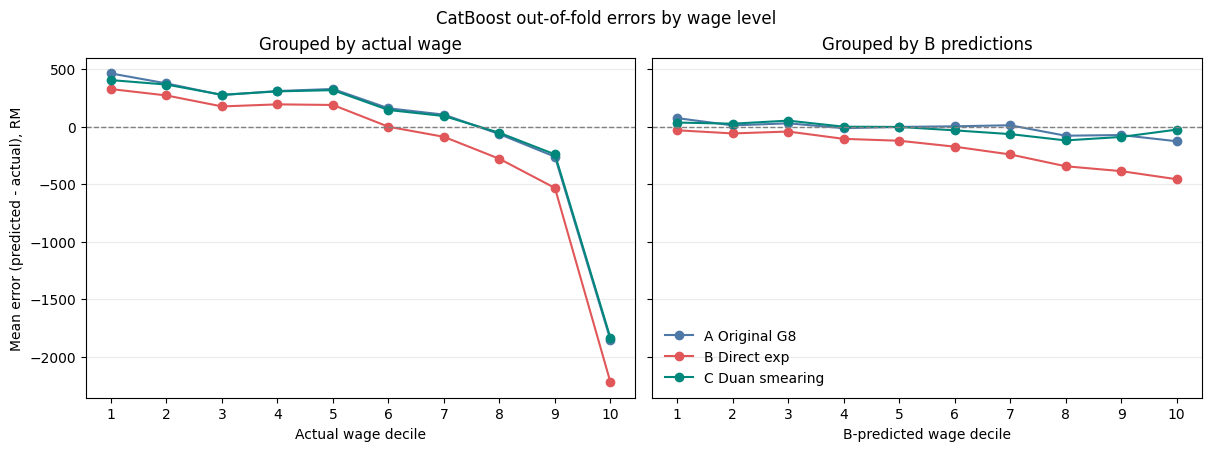

Changes from B to C by outer fold
            Overall MAE change (RM)  D10 MAE change (RM)  D10 mean error change (RM)
Outer Fold                                                                          
1                             14.85              -194.42                      380.56
2                             13.01              -205.70                      395.36
3                             19.87              -138.60                      370.21
4                             16.94              -203.68                      417.35
5                             14.33              -196.31                      361.19
Section 5A passed.


In [5]:
# Week 7 - Section 5A: Diagnose OOF residuals across wage levels

import matplotlib.pyplot as plt

methods = ["A Original G8", "B Direct exp", "C Duan smearing"]
diagnostics = w7_all_predictions.copy()

# Prediction error = predicted wage minus actual wage.
w7_errors = diagnostics[methods].sub(diagnostics["Actual G8"], axis=0)

# Use the same B-based groups to compare the same people across methods.
w7_b_prediction_decile = pd.qcut(
    diagnostics["B Direct exp"], q=10, labels=False, duplicates="drop"
) + 1

w7_bias_by_actual = w7_errors.groupby(diagnostics["Actual Wage Decile"]).mean()
w7_bias_by_prediction = w7_errors.groupby(w7_b_prediction_decile).mean()

b_error = w7_errors["B Direct exp"]
c_error = w7_errors["C Duan smearing"]
fold_id = diagnostics["Outer Fold"]
d10 = diagnostics["Actual Wage Decile"].eq(10)

w7_fold_changes = pd.DataFrame({
    "Overall MAE change (RM)": (
        c_error.abs() - b_error.abs()
    ).groupby(fold_id).mean(),
    "D10 MAE change (RM)": (
        c_error[d10].abs() - b_error[d10].abs()
    ).groupby(fold_id[d10]).mean(),
    "D10 mean error change (RM)": (
        c_error[d10] - b_error[d10]
    ).groupby(fold_id[d10]).mean(),
})

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.4), sharey=True, constrained_layout=True
)
colors = ["#4e79a7", "#e15759", "#00877c"]

for ax, table, title, xlabel in [
    (axes[0], w7_bias_by_actual, "Grouped by actual wage", "Actual wage decile"),
    (axes[1], w7_bias_by_prediction, "Grouped by B predictions", "B-predicted wage decile"),
]:
    for method, color in zip(methods, colors):
        ax.plot(table.index, table[method], marker="o", label=method, color=color)

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel=xlabel, xticks=table.index)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Mean error (predicted - actual), RM")
axes[1].legend(frameon=False)
fig.suptitle("CatBoost out-of-fold errors by wage level")
plt.show()

print("Changes from B to C by outer fold")
print(w7_fold_changes.round(2).to_string())
print("Section 5A passed.")

In [7]:
# Week 7 - Section 5B: Compare MAE and RMSE for inner-CV selection

w7_rmse_predictions = w7_all_predictions["B Direct exp"].copy()
w7_rmse_predictions.name = "RMSE-selected"
selection_rows = []

for fold, (train_ids, val_ids) in w7_outer_splits.items():
    search_path = (
        W6_RUN / "nested_cv" / f"outer_fold_{fold:02d}"
        / "inner_search_results" / "catboost__ln_g8.csv"
    )
    search = pd.read_csv(search_path)
    assert len(search) == w6_protocol["search_budget"]["CatBoost"]

    mae_best = search.loc[search["rank_test_MAE"].eq(1)]
    rmse_best = search.loc[search["rank_test_RMSE"].eq(1)]
    assert len(mae_best) == len(rmse_best) == 1, f"Fold {fold}: check search ranks"

    mae_row = mae_best.iloc[0]
    rmse_row = rmse_best.iloc[0]
    mae_params = json.loads(mae_row["params_json"])
    rmse_params = json.loads(rmse_row["params_json"])
    assert mae_params == w6_catboost_params[fold]["ln(G8)"]

    changed = mae_params != rmse_params
    action = "refitting RMSE choice" if changed else "reusing B predictions"
    print(f"Fold {fold}: {action}", flush=True)

    if changed:
        model = w7_make_catboost(rmse_params)
        y_log = np.log(w7_y.loc[train_ids].to_numpy(dtype=float))
        model.fit(w7_X.loc[train_ids], y_log, cat_features=w7_cat_features)
        prediction = np.exp(model.predict(w7_X.loc[val_ids]))
        assert np.isfinite(prediction).all()
        w7_rmse_predictions.loc[val_ids] = prediction

    selection_rows.append({
        "Outer Fold": fold,
        "Parameters changed": changed,
        "Inner RMSE: MAE choice": -mae_row["mean_test_RMSE"],
        "Inner RMSE: RMSE choice": -rmse_row["mean_test_RMSE"],
    })

w7_selection_by_fold = pd.DataFrame(selection_rows)

selection_eval = w7_all_predictions[["Actual G8", "Actual Wage Decile"]].copy()
selection_eval["MAE-selected"] = w7_all_predictions["B Direct exp"]
selection_eval["RMSE-selected"] = w7_rmse_predictions

rows = []
for group, data in [
    ("All", selection_eval),
    ("D1", selection_eval.loc[selection_eval["Actual Wage Decile"].eq(1)]),
    ("D10", selection_eval.loc[selection_eval["Actual Wage Decile"].eq(10)]),
]:
    for method in ("MAE-selected", "RMSE-selected"):
        error = data[method] - data["Actual G8"]
        rows.append({
            "Group": group,
            "Selection": method,
            "Rows": len(data),
            "MAE (RM)": error.abs().mean(),
            "RMSE (RM)": np.sqrt(error.pow(2).mean()),
            "Mean error (RM)": error.mean(),
            "Underpredicted (%)": 100 * error.lt(0).mean(),
        })

w7_selection_summary = pd.DataFrame(rows)
print("\nInner-CV choices by fold")
print(w7_selection_by_fold.round(2).to_string(index=False))
print("\nFive-fold OOF comparison (direct exp for both)")
print(w7_selection_summary.round(2).to_string(index=False))
print("Section 5B passed.")
print(w7_selection_summary.round(2).to_string(index=False))

Fold 1: refitting RMSE choice
Fold 2: reusing B predictions
Fold 3: reusing B predictions
Fold 4: refitting RMSE choice
Fold 5: reusing B predictions

Inner-CV choices by fold
 Outer Fold  Parameters changed  Inner RMSE: MAE choice  Inner RMSE: RMSE choice
          1                True                 1571.52                  1569.23
          2               False                 1578.10                  1578.10
          3               False                 1510.44                  1510.44
          4                True                 1609.56                  1604.99
          5               False                 1606.22                  1606.22

Five-fold OOF comparison (direct exp for both)
Group     Selection  Rows  MAE (RM)  RMSE (RM)  Mean error (RM)  Underpredicted (%)
  All  MAE-selected 21940    749.66    1579.51          -197.23               48.59
  All RMSE-selected 21940    750.03    1579.48          -194.95               48.63
   D1  MAE-selected  2194    345.61   

In [8]:
# Week 7 - Section 6: Explain remaining high-wage errors with OOF SHAP

from catboost import Pool

high_wage = w7_all_predictions.loc[
    w7_all_predictions["Actual Wage Decile"].eq(10)
].copy()
high_wage["C error"] = high_wage["C Duan smearing"] - high_wage["Actual G8"]
high_wage["C relative error"] = high_wage["C error"] / high_wage["Actual G8"]

top_features = [
    "Industry_Section", "Occupation_Group", "Educational_Attainment", "Age"
]
feature_positions = [w7_X.columns.get_loc(name) for name in top_features]
case_tables = []
additivity_errors = []

for fold, data in high_wage.groupby("Outer Fold", sort=True):
    severe = data.loc[data["C relative error"].le(-0.30)].sort_values(
        "C relative error", kind="stable"
    )
    accurate = data.loc[data["C relative error"].abs().le(0.10)]
    pair = None

    # Choose the most underpredicted eligible case and its closest wage match.
    for severe_id, row in severe.iterrows():
        distance = (accurate["Actual G8"] - row["Actual G8"]).abs()
        eligible = distance.loc[distance.le(0.10 * row["Actual G8"])]
        if not eligible.empty:
            pair = [severe_id, eligible.idxmin()]
            break

    if pair is None:
        print(f"Fold {fold}: no case pair meets the matching rules.")
        continue

    train_ids, val_ids = w7_outer_splits[fold]
    assert set(pair).issubset(val_ids) and set(pair).isdisjoint(train_ids)
    _, factor, fold_model = w7_fold_runs[fold]

    X_cases = w7_X.loc[pair]
    case_pool = Pool(X_cases, cat_features=w7_cat_features)
    native_shap = fold_model.get_feature_importance(
        data=case_pool, type="ShapValues", thread_count=1
    )
    assert native_shap.shape == (len(pair), w7_X.shape[1] + 1)

    contributions = native_shap[:, :-1]
    log_baseline = native_shap[:, -1]
    reconstructed_b = log_baseline + contributions.sum(axis=1)
    reconstructed_c = reconstructed_b + np.log(factor)
    case_rows = data.loc[pair]

    expected_b = np.log(case_rows["B Direct exp"].to_numpy())
    expected_c = np.log(case_rows["C Duan smearing"].to_numpy())
    np.testing.assert_allclose(reconstructed_b, expected_b, rtol=0, atol=1e-6)
    np.testing.assert_allclose(reconstructed_c, expected_c, rtol=0, atol=1e-6)
    additivity_errors.extend(np.abs(reconstructed_c - expected_c))

    result = case_rows[
        ["Outer Fold", "Actual G8", "C Duan smearing", "C error"]
    ].copy()
    result.insert(1, "Case", ["Severe underprediction", "Accurate match"])
    for name, pos in zip(top_features, feature_positions):
        result[f"SHAP {name}"] = contributions[:, pos]
    case_tables.append(result)

if not case_tables:
    raise RuntimeError("No wage-matched pairs were found.")

w7_shap_cases = pd.concat(case_tables, verify_integrity=True)
w7_shap_case_features = w7_X.loc[w7_shap_cases.index, top_features].copy()
shap_columns = [f"SHAP {name}" for name in top_features]
w7_shap_case_means = w7_shap_cases.groupby("Case")[shap_columns].mean()

print(f"Matched pairs: {len(w7_shap_cases) // 2}")
print(f"Maximum log-scale reconstruction error: {max(additivity_errors):.2e}")
print(w7_shap_cases.round(3).to_string())

print("\nFeature values for the cases")
print(w7_shap_case_features.to_string())

print("\nMean log-scale SHAP within these illustrative cases")
print(w7_shap_case_means.round(3).to_string())
print("Section 6 passed.")

Matched pairs: 5
Maximum log-scale reconstruction error: 5.33e-15
               Outer Fold                    Case  Actual G8  C Duan smearing   C error  SHAP Industry_Section  SHAP Occupation_Group  SHAP Educational_Attainment  SHAP Age
source_row_id                                                                                                                                                               
85                      1  Severe underprediction   7390.000         1704.227 -5685.773                 -0.285                  0.069                        0.221    -0.124
20103                   1          Accurate match   7392.000         7162.941  -229.059                  0.321                  0.338                        0.204     0.175
20061                   2  Severe underprediction   6567.000         1821.451 -4745.549                 -0.098                 -0.086                       -0.085    -0.203
4816                    2          Accurate match   6584.000         

In [9]:
# Week 7 - Section 7: Attribute pooled MAE changes by actual-wage decile

p = w7_all_predictions
decile = p["Actual Wage Decile"]

assert len(p) == 21_940 and p.index.is_unique
assert decile.notna().all() and set(decile) == set(range(1, 11))

prediction_columns = ["A Original G8", "B Direct exp", "C Duan smearing"]
absolute_errors = p[prediction_columns].sub(p["Actual G8"], axis=0).abs()
absolute_errors.columns = ["A MAE", "B MAE", "C MAE"]
assert np.isfinite(absolute_errors.to_numpy()).all()

group_mae = absolute_errors.groupby(decile).mean()
group_size = decile.value_counts().sort_index()

table = group_mae.copy()
table.insert(0, "Rows", group_size)
table.insert(1, "Mean actual G8", p["Actual G8"].groupby(decile).mean())

ab_col = "A to B: contribution"
bc_col = "B to C: contribution"
group_share = group_size / len(p)

table[ab_col] = (group_mae["A MAE"] - group_mae["B MAE"]) * group_share
table[bc_col] = (group_mae["B MAE"] - group_mae["C MAE"]) * group_share

pooled_mae = absolute_errors.mean()
np.testing.assert_allclose(
    table[[ab_col, bc_col]].sum().to_numpy(),
    [
        pooled_mae["A MAE"] - pooled_mae["B MAE"],
        pooled_mae["B MAE"] - pooled_mae["C MAE"],
    ],
    rtol=0,
    atol=1e-9,
)

w7_mae_deciles = table
print("MAE and contribution to pooled MAE change (RM)")
print("Positive contribution = lower MAE after the switch.")
print(w7_mae_deciles.round(2).to_string())

print("\nNet pooled contributions")
print(table[[ab_col, bc_col]].sum().round(2).to_string())

# Two definitions of lower wages: bottom 30% and bottom 50%.
# The denominator is the sum of positive A-to-B contributions.
ab_positive = table[ab_col].clip(lower=0)
gross_gain = ab_positive.sum()

print("\nWhere the A-to-B improvements came from")
for upper in (3, 5):
    net = table.loc[1:upper, ab_col].sum()
    share = (
        100 * ab_positive.loc[1:upper].sum() / gross_gain
        if gross_gain > 0 else np.nan
    )
    print(
        f"D1-D{upper}: net RM {net:.2f}; "
        f"share of positive contributions {share:.1f}%"
    )

print("Section 7 passed.")

MAE and contribution to pooled MAE change (RM)
Positive contribution = lower MAE after the switch.
                    Rows  Mean actual G8    A MAE    B MAE    C MAE  A to B: contribution  B to C: contribution
Actual Wage Decile                                                                                             
1                   2194          935.43   471.17   345.61   413.68                 12.56                 -6.81
2                   2196         1259.93   400.83   312.08   387.80                  8.88                 -7.58
3                   2199         1463.28   346.72   271.28   325.14                  7.56                 -5.40
4                   2281         1634.77   419.73   334.19   391.10                  8.89                 -5.92
5                   2126         1897.57   537.28   439.20   490.04                  9.50                 -4.93
6                   2191         2360.01   645.64   566.15   582.90                  7.94                 -1.67
7    

In [10]:
from hashlib import sha256
import json
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder


def w7_lightgbm_pilot():
    required = (
        "W6_RUN", "w6_protocol", "w7_X", "w7_y", "w7_dev_raw",
        "w7_dev_ids", "w7_outer_splits", "w7_deciles",
    )
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError("Week 7 kernel variables missing: " + ", ".join(missing))

    train_ids, val_ids = w7_outer_splits[1]
    fold_dir = W6_RUN / "nested_cv" / "outer_fold_01"
    fold_record = json.loads((fold_dir / "fold_complete.json").read_text(encoding="utf-8"))

    assert len(train_ids) == 17_552 and len(val_ids) == 4_388
    assert set(train_ids).isdisjoint(val_ids)
    assert set(train_ids) | set(val_ids) == set(w7_dev_ids)
    for role, ids in (("Train", train_ids), ("Validation", val_ids)):
        digest = sha256(",".join(map(str, ids)).encode("utf-8")).hexdigest()
        assert digest == fold_record[f"Outer {role} Index SHA256"], role

    nominal = [
        "State", "Strata", "Sex", "Ethnic_Group", "Marital_Status",
        "Occupation_Group", "Industry_Section",
    ]
    features = w7_X.loc[w7_dev_ids, w6_protocol["features"]].copy()
    for name in nominal:
        if name in w7_dev_raw.columns:
            features[name] = w7_dev_raw.loc[features.index, name]

    x_train = features.loc[train_ids]
    x_val = features.loc[val_ids]
    y_train = w7_y.loc[train_ids].to_numpy(dtype=float)
    y_val = w7_y.loc[val_ids].to_numpy(dtype=float)
    groups = w7_deciles.loc[val_ids, "Actual Wage Decile"].to_numpy()

    assert np.isfinite(y_train).all() and (y_train > 0).all()
    assert np.isfinite(y_val).all() and set(groups) == set(range(1, 11))

    candidates = pd.read_csv(fold_dir / "candidate_summary.csv")
    candidates = candidates.loc[candidates["Model"].eq("LightGBM")].set_index("Target")
    assert candidates.index.is_unique and set(candidates.index) == {"Original G8", "ln(G8)"}

    def make_model(target):
        params = json.loads(candidates.loc[target, "Best Params"])
        prefix = "regressor__model__" if target == "ln(G8)" else "model__"
        assert params and all(key.startswith(prefix) for key in params)
        params = {key[len(prefix):]: value for key, value in params.items()}

        prep = ColumnTransformer(
            [
                ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=True), nominal),
                ("ordinal", OrdinalEncoder(
                    categories=[[1, 2, 3, 4]],
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ), ["Educational_Attainment"]),
                ("numeric", "passthrough", ["Age"]),
            ],
            remainder="drop",
            sparse_threshold=1.0,
            verbose_feature_names_out=False,
        )
        return Pipeline([
            ("preprocessing", prep),
            ("model", LGBMRegressor(
                objective="regression", random_state=w6_protocol["search_seed"],
                n_jobs=1, verbosity=-1, **params,
            )),
        ])

    print(f"Fold 1: {len(train_ids):,} training rows, {len(val_ids):,} validation rows verified.")
    inner = KFold(n_splits=3, shuffle=True, random_state=w6_protocol["inner_seed"])
    log_train = np.log(y_train)
    calibration = np.full(len(y_train), np.nan)
    inner_mae = []

    for fit_pos, cal_pos in inner.split(x_train):
        model = make_model("ln(G8)").fit(x_train.iloc[fit_pos], log_train[fit_pos])
        log_pred = model.predict(x_train.iloc[cal_pos])
        calibration[cal_pos] = log_pred
        inner_mae.append(np.abs(np.exp(log_pred) - y_train[cal_pos]).mean())

    assert np.isfinite(calibration).all()
    rebuilt = float(np.mean(inner_mae))
    saved = float(candidates.loc["ln(G8)", "Inner CV MAE"])
    print(f"LightGBM log inner CV MAE: rebuilt RM{rebuilt:.4f}; Week 6 RM{saved:.4f}")
    if not np.isclose(rebuilt, saved, atol=0.05, rtol=0):
        raise RuntimeError("Week 6 inner-CV baseline did not reproduce; stopped before outer fits.")

    factor = float(np.mean(np.exp(log_train - calibration)))
    assert np.isfinite(factor) and factor > 0

    pred_a = make_model("Original G8").fit(x_train, y_train).predict(x_val)
    model_b = make_model("ln(G8)").fit(x_train, log_train)
    pred_b = np.exp(model_b.predict(x_val))
    methods = ["A Original G8", "B Direct exp", "C Duan smearing"]

    predictions = pd.DataFrame({
        "Actual G8": y_val, "Actual Wage Decile": groups,
        methods[0]: pred_a, methods[1]: pred_b, methods[2]: factor * pred_b,
    }, index=pd.Index(val_ids, name="source_row_id"))
    assert predictions.index.is_unique and np.isfinite(predictions.to_numpy()).all()

    rows = []
    for name, mask in [
        ("All", np.ones(len(y_val), dtype=bool)),
        ("D1", groups == 1),
        ("D10", groups == 10),
    ]:
        for method in methods:
            error = predictions[method].to_numpy()[mask] - y_val[mask]
            rows.append([
                name, method, len(error), np.abs(error).mean(),
                np.sqrt(np.square(error).mean()), error.mean(), 100 * (error < 0).mean(),
            ])

    summary = pd.DataFrame(rows, columns=[
        "Group", "Method", "Rows", "MAE (RM)", "RMSE (RM)",
        "Mean error (RM)", "Underpredicted (%)",
    ])
    print(f"Fold 1 smearing factor: {factor:.6f}")
    print(summary.round(2).to_string(index=False))
    return predictions, summary, factor


w7_lgbm_fold1_predictions, w7_lgbm_fold1_summary, w7_lgbm_fold1_factor = w7_lightgbm_pilot()

Fold 1: 17,552 training rows, 4,388 validation rows verified.
LightGBM log inner CV MAE: rebuilt RM761.8738; Week 6 RM761.8738
Fold 1 smearing factor: 1.061227
Group          Method  Rows  MAE (RM)  RMSE (RM)  Mean error (RM)  Underpredicted (%)
  All   A Original G8  4388    806.49    1546.53            12.50               41.13
  All    B Direct exp  4388    756.39    1573.74          -181.12               46.88
  All C Duan smearing  4388    775.74    1557.64            -9.25               37.85
   D1   A Original G8   445    487.20     720.95           464.21                9.21
   D1    B Direct exp   445    360.03     547.43           344.05                8.76
   D1 C Duan smearing   445    430.62     618.31           422.56                5.84
  D10   A Original G8   445   2187.50    3876.23         -1690.84               75.28
  D10    B Direct exp   445   2382.59    4190.36         -2132.11               82.70
  D10 C Duan smearing   445   2202.79    4037.62         -1748.43 

In [11]:
# Week 7 - Section 8A: Complete the LightGBM retransformation comparison
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display


def w7_run_wage_fold(model_name, fold):
    train_ids, val_ids = w7_outer_splits[fold]
    fold_dir = W6_RUN / "nested_cv" / f"outer_fold_{fold:02d}"
    manifest = json.loads((fold_dir / "fold_complete.json").read_text(encoding="utf-8"))
    assert (len(train_ids), len(val_ids)) == (17_552, 4_388)
    assert set(train_ids).isdisjoint(val_ids)
    assert set(train_ids) | set(val_ids) == set(w7_dev_ids)
    for role, ids in (("Train", train_ids), ("Validation", val_ids)):
        digest = sha256(",".join(map(str, ids)).encode("utf-8")).hexdigest()
        assert digest == manifest[f"Outer {role} Index SHA256"], (fold, role)

    nominal = [
        "State", "Strata", "Sex", "Ethnic_Group", "Marital_Status",
        "Occupation_Group", "Industry_Section",
    ]
    features = w7_X.loc[w7_dev_ids, w6_protocol["features"]].copy()
    for name in nominal:
        if name in w7_dev_raw.columns:
            features[name] = w7_dev_raw.loc[features.index, name]
    x_train, x_val = features.loc[train_ids], features.loc[val_ids]
    y_train = w7_y.loc[train_ids].to_numpy(dtype=float)
    y_val = w7_y.loc[val_ids].to_numpy(dtype=float)
    deciles = w7_deciles.loc[val_ids, "Actual Wage Decile"].to_numpy()
    assert np.isfinite(y_train).all() and (y_train > 0).all()
    assert np.isfinite(y_val).all() and (y_val > 0).all()
    assert set(deciles) == set(range(1, 11))

    candidates = pd.read_csv(fold_dir / "candidate_summary.csv")
    candidates = candidates.loc[candidates["Model"].eq(model_name)].set_index("Target")
    assert candidates.index.is_unique and set(candidates.index) == {"Original G8", "ln(G8)"}

    def make_pipeline(target):
        params = json.loads(candidates.loc[target, "Best Params"])
        prefix = "regressor__model__" if target == "ln(G8)" else "model__"
        assert params and all(key.startswith(prefix) for key in params)
        params = {key[len(prefix):]: value for key, value in params.items()}
        preprocessing = ColumnTransformer(
            [
                ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=True), nominal),
                ("ordinal", OrdinalEncoder(
                    categories=[[1, 2, 3, 4]],
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ), ["Educational_Attainment"]),
                ("numeric", "passthrough", ["Age"]),
            ],
            remainder="drop",
            sparse_threshold=1.0,
            verbose_feature_names_out=False,
        )
        seed = w6_protocol["search_seed"]
        if model_name == "LightGBM":
            model = LGBMRegressor(objective="regression", random_state=seed, n_jobs=1, verbosity=-1, **params)
        else:
            assert model_name == "Random Forest"
            model = RandomForestRegressor(random_state=seed, n_jobs=2, **params)
        return Pipeline([("preprocessing", preprocessing), ("model", model)])

    inner = KFold(n_splits=3, shuffle=True, random_state=w6_protocol["inner_seed"])
    log_train = np.log(y_train)
    calibration = np.full(len(y_train), np.nan)
    inner_mae = []
    for split, (fit_pos, cal_pos) in enumerate(inner.split(x_train), start=1):
        print(f"{model_name} fold {fold}: calibration {split}/3", flush=True)
        model = make_pipeline("ln(G8)").fit(x_train.iloc[fit_pos], log_train[fit_pos])
        log_pred = model.predict(x_train.iloc[cal_pos])
        calibration[cal_pos] = log_pred
        inner_mae.append(np.abs(np.exp(log_pred) - y_train[cal_pos]).mean())

    assert np.isfinite(calibration).all()
    rebuilt = float(np.mean(inner_mae))
    saved = float(candidates.loc["ln(G8)", "Inner CV MAE"])
    print(f"{model_name} fold {fold}: inner MAE {rebuilt:.4f} vs Week 6 {saved:.4f}", flush=True)
    if not np.isclose(rebuilt, saved, atol=0.05, rtol=0):
        raise RuntimeError(f"{model_name} fold {fold}: Week 6 inner CV MAE mismatch")

    factor = float(np.exp(log_train - calibration).mean())
    assert np.isfinite(factor) and factor > 0
    print(f"{model_name} fold {fold}: fitting original and log models", flush=True)
    pred_a = make_pipeline("Original G8").fit(x_train, y_train).predict(x_val)
    pred_b = np.exp(make_pipeline("ln(G8)").fit(x_train, log_train).predict(x_val))
    predictions = pd.DataFrame({
        "Actual G8": y_val,
        "Actual Wage Decile": deciles,
        "A Original G8": pred_a,
        "B Direct exp": pred_b,
        "C Duan smearing": factor * pred_b,
    }, index=pd.Index(val_ids, name="source_row_id"))
    assert predictions.index.is_unique and np.isfinite(predictions.to_numpy()).all()
    assert (predictions[["B Direct exp", "C Duan smearing"]] > 0).all().all()
    print(f"{model_name} fold {fold}: complete (smearing factor {factor:.6f})", flush=True)
    return predictions, factor


def w7_pool_wage_folds(fold_runs):
    assert set(fold_runs) == set(range(1, 6))
    frames = []
    for fold, (predictions, factor) in sorted(fold_runs.items()):
        val_ids = w7_outer_splits[fold][1]
        assert predictions.index.equals(pd.Index(val_ids, name="source_row_id"))
        np.testing.assert_allclose(predictions["C Duan smearing"], factor * predictions["B Direct exp"])
        frames.append(predictions.assign(**{"Outer Fold": fold}))
    pooled = pd.concat(frames, verify_integrity=True).sort_index()
    columns = ["Actual G8", "Actual Wage Decile", "Outer Fold"]
    pd.testing.assert_frame_equal(pooled[columns], w7_all_predictions.sort_index()[columns], check_dtype=False)
    return pooled


w7_lgbm_runs = globals().get("w7_lgbm_runs", {})
w7_lgbm_runs[1] = (w7_lgbm_fold1_predictions, w7_lgbm_fold1_factor)
print("LightGBM fold 1: reusing the verified pilot", flush=True)
for fold in range(2, 6):
    if fold not in w7_lgbm_runs:
        w7_lgbm_runs[fold] = w7_run_wage_fold("LightGBM", fold)
w7_lgbm_predictions = w7_pool_wage_folds(w7_lgbm_runs)
w7_lgbm_summary = w7_summarize_predictions(w7_lgbm_predictions)
display(w7_lgbm_summary.round(2))
print(f"Section 8A passed. LightGBM: {len(w7_lgbm_predictions):,} verified OOF rows.")


LightGBM fold 1: reusing the verified pilot
LightGBM fold 2: calibration 1/3
LightGBM fold 2: calibration 2/3
LightGBM fold 2: calibration 3/3
LightGBM fold 2: inner MAE 763.6419 vs Week 6 763.6419
LightGBM fold 2: fitting original and log models
LightGBM fold 2: complete (smearing factor 1.059968)
LightGBM fold 3: calibration 1/3
LightGBM fold 3: calibration 2/3
LightGBM fold 3: calibration 3/3
LightGBM fold 3: inner MAE 755.8067 vs Week 6 755.8067
LightGBM fold 3: fitting original and log models
LightGBM fold 3: complete (smearing factor 1.059824)
LightGBM fold 4: calibration 1/3
LightGBM fold 4: calibration 2/3
LightGBM fold 4: calibration 3/3
LightGBM fold 4: inner MAE 767.4063 vs Week 6 767.4063
LightGBM fold 4: fitting original and log models
LightGBM fold 4: complete (smearing factor 1.062676)
LightGBM fold 5: calibration 1/3
LightGBM fold 5: calibration 2/3
LightGBM fold 5: calibration 3/3
LightGBM fold 5: inner MAE 768.9554 vs Week 6 768.9554
LightGBM fold 5: fitting original 

,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,All,A Original G8,21940,804.34,1564.42,4.87,41.57
1,All,B Direct exp,21940,754.25,1575.35,-189.94,48.10
2,All,C Duan smearing,21940,769.36,1557.42,-17.28,38.44
3,D1,A Original G8,2194,480.11,681.62,461.58,8.39
4,D1,B Direct exp,2194,350.74,499.59,330.62,10.85
5,D1,C Duan smearing,2194,418.25,568.71,407.96,6.34
6,D10,A Original G8,2194,2235.32,3983.90,-1817.07,77.44
7,D10,B Direct exp,2194,2427.87,4251.29,-2220.00,84.73
8,D10,C Duan smearing,2194,2228.69,4093.03,-1839.75,74.98


Section 8A passed. LightGBM: 21,940 verified OOF rows.


In [12]:
# Week 7 - Section 8B: Verify Random Forest on outer Fold 1
w7_rf_runs = globals().get("w7_rf_runs", {})
if 1 not in w7_rf_runs:
    w7_rf_runs[1] = w7_run_wage_fold("Random Forest", 1)
w7_rf_pilot_predictions, w7_rf_pilot_factor = w7_rf_runs[1]
display(w7_summarize_predictions(w7_rf_pilot_predictions).round(2))
print(f"Section 8B passed. Random Forest pilot: {len(w7_rf_pilot_predictions):,} verified OOF rows.")


Random Forest fold 1: calibration 1/3
Random Forest fold 1: calibration 2/3
Random Forest fold 1: calibration 3/3
Random Forest fold 1: inner MAE 785.3675 vs Week 6 785.3675
Random Forest fold 1: fitting original and log models
Random Forest fold 1: complete (smearing factor 1.065464)


,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,All,A Original G8,4388,803.74,1578.24,19.84,39.81
1,All,B Direct exp,4388,775.50,1606.38,-192.06,47.06
2,All,C Duan smearing,4388,793.24,1589.11,-9.01,37.67
3,D1,A Original G8,445,501.05,738.80,494.04,5.84
4,D1,B Direct exp,445,394.12,596.43,379.96,8.76
5,D1,C Duan smearing,445,472.72,675.82,466.26,4.49
6,D10,A Original G8,445,2218.59,3969.24,-1728.30,77.53
7,D10,B Direct exp,445,2465.55,4270.58,-2241.48,85.39
8,D10,C Duan smearing,445,2253.68,4105.48,-1838.41,76.40


Section 8B passed. Random Forest pilot: 4,388 verified OOF rows.


In [13]:
# Week 7 - Section 8C: Complete the Random Forest retransformation comparison
assert 1 in w7_rf_runs, "Verify the Random Forest pilot first."
print("Random Forest fold 1: reusing the verified pilot", flush=True)
for fold in range(2, 6):
    if fold not in w7_rf_runs:
        w7_rf_runs[fold] = w7_run_wage_fold("Random Forest", fold)
w7_rf_predictions = w7_pool_wage_folds(w7_rf_runs)
w7_rf_summary = w7_summarize_predictions(w7_rf_predictions)
display(w7_rf_summary.round(2))
print(f"Section 8C passed. Random Forest: {len(w7_rf_predictions):,} verified OOF rows.")


Random Forest fold 1: reusing the verified pilot
Random Forest fold 2: calibration 1/3
Random Forest fold 2: calibration 2/3
Random Forest fold 2: calibration 3/3
Random Forest fold 2: inner MAE 781.9993 vs Week 6 781.9993
Random Forest fold 2: fitting original and log models
Random Forest fold 2: complete (smearing factor 1.065476)
Random Forest fold 3: calibration 1/3
Random Forest fold 3: calibration 2/3
Random Forest fold 3: calibration 3/3
Random Forest fold 3: inner MAE 778.2021 vs Week 6 778.2021
Random Forest fold 3: fitting original and log models
Random Forest fold 3: complete (smearing factor 1.063944)
Random Forest fold 4: calibration 1/3
Random Forest fold 4: calibration 2/3
Random Forest fold 4: calibration 3/3
Random Forest fold 4: inner MAE 787.5968 vs Week 6 787.5968
Random Forest fold 4: fitting original and log models
Random Forest fold 4: complete (smearing factor 1.064811)
Random Forest fold 5: calibration 1/3
Random Forest fold 5: calibration 2/3
Random Forest fol

,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,All,A Original G8,21940,794.48,1575.00,5.14,40.60
1,All,B Direct exp,21940,767.85,1603.44,-201.95,47.77
2,All,C Duan smearing,21940,783.68,1584.34,-19.54,38.00
3,D1,A Original G8,2194,481.70,709.30,471.02,6.43
4,D1,B Direct exp,2194,377.19,552.35,359.50,10.16
5,D1,C Duan smearing,2194,452.27,628.44,443.36,5.20
6,D10,A Original G8,2194,2241.27,4020.40,-1835.24,78.44
7,D10,B Direct exp,2194,2500.54,4323.76,-2298.21,85.73
8,D10,C Duan smearing,2194,2285.28,4156.82,-1899.69,76.03


Section 8C passed. Random Forest: 21,940 verified OOF rows.


In [14]:
# Week 7 - Section 8D: Compare retransformation effects across model families
w7_comparison_oof = {
    "CatBoost": w7_all_predictions.sort_index(),
    "LightGBM": w7_lgbm_predictions,
    "Random Forest": w7_rf_predictions,
}
w7_comparison_summary = pd.concat([
    w7_summarize_predictions(predictions).assign(Model=model)
    for model, predictions in w7_comparison_oof.items()
], ignore_index=True)
w7_comparison_summary = w7_comparison_summary[[
    "Model", "Group", "Method", "Rows", "MAE (RM)", "RMSE (RM)",
    "Mean error (RM)", "Underpredicted (%)",
]]
assert len(w7_comparison_summary) == 27
assert set(w7_comparison_summary.loc[w7_comparison_summary["Group"].eq("All"), "Rows"]) == {21_940}
display(w7_comparison_summary.round(2))

# C minus B compares two retransformation methods on the same fitted log models.
w7_smearing_changes = []
for model, predictions in w7_comparison_oof.items():
    fold_changes = []
    for fold, outer in predictions.groupby("Outer Fold"):
        assert len(outer) == 4_388
        b_abs = (outer["B Direct exp"] - outer["Actual G8"]).abs()
        c_abs = (outer["C Duan smearing"] - outer["Actual G8"]).abs()
        d10 = outer["Actual Wage Decile"].eq(10)
        fold_changes.append({
            "Outer Fold": fold,
            "All: MAE change": (c_abs - b_abs).mean(),
            "D10: MAE change": (c_abs - b_abs).loc[d10].mean(),
        })
    by_fold = pd.DataFrame(fold_changes)
    assert by_fold["Outer Fold"].tolist() == [1, 2, 3, 4, 5]
    metrics = w7_summarize_predictions(predictions).set_index(["Group", "Method"])
    b = metrics.xs("B Direct exp", level="Method")
    c = metrics.xs("C Duan smearing", level="Method")
    w7_smearing_changes.append({
        "Model": model,
        "All: MAE change (RM)": c.loc["All", "MAE (RM)"] - b.loc["All", "MAE (RM)"],
        "All: mean error B (RM)": b.loc["All", "Mean error (RM)"],
        "All: mean error C (RM)": c.loc["All", "Mean error (RM)"],
        "D10: MAE change (RM)": c.loc["D10", "MAE (RM)"] - b.loc["D10", "MAE (RM)"],
        "D10: mean error C (RM)": c.loc["D10", "Mean error (RM)"],
        "Folds with higher overall MAE": int(by_fold["All: MAE change"].gt(0).sum()),
        "Folds with lower D10 MAE": int(by_fold["D10: MAE change"].lt(0).sum()),
    })
w7_smearing_changes = pd.DataFrame(w7_smearing_changes)
display(w7_smearing_changes.round(2))
print("Section 8D passed. Three model families compared on the same five development folds.")


,Model,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,CatBoost,All,A Original G8,21940,785.45,1574.18,-17.33,41.83
1,CatBoost,All,B Direct exp,21940,749.66,1579.51,-197.23,48.59
2,CatBoost,All,C Duan smearing,21940,765.46,1561.62,-22.92,38.51
3,CatBoost,D1,A Original G8,2194,471.17,644.76,461.36,5.70
4,CatBoost,D1,B Direct exp,2194,345.61,489.88,325.57,11.17
5,CatBoost,D1,C Duan smearing,2194,413.68,559.36,403.52,6.34
6,CatBoost,D10,A Original G8,2194,2230.79,4067.10,-1853.62,77.85
7,CatBoost,D10,B Direct exp,2194,2448.90,4277.49,-2221.37,83.36
8,CatBoost,D10,C Duan smearing,2194,2261.45,4120.63,-1836.62,74.07
9,LightGBM,All,A Original G8,21940,804.34,1564.42,4.87,41.57


,Model,All: MAE change (RM),All: mean error B (RM),All: mean error C (RM),D10: MAE change (RM),D10: mean error C (RM),Folds with higher overall MAE,Folds with lower D10 MAE
0,CatBoost,15.80,-197.23,-22.92,-187.45,-1836.62,5,5
1,LightGBM,15.11,-189.94,-17.28,-199.18,-1839.75,5,5
2,Random Forest,15.82,-201.95,-19.54,-215.26,-1899.69,5,5


Section 8D passed. Three model families compared on the same five development folds.


In [15]:
# Week 7 - Section 9: Isolate target-scale and parameter effects in CatBoost
from IPython.display import display


def w7_error_metrics(actual, predicted):
    error = np.asarray(predicted) - np.asarray(actual)
    return {
        "Rows": len(error),
        "MAE (RM)": float(np.abs(error).mean()),
        "RMSE (RM)": float(np.sqrt(np.square(error).mean())),
        "Mean error (RM)": float(error.mean()),
        "Underpredicted (%)": float(100 * (error < 0).mean()),
    }


def w7_cat_fit(train_x, train_y, params, sample_weight=None, cat_features=None):
    model = w7_make_catboost(params)
    model.fit(
        train_x, train_y, sample_weight=sample_weight,
        cat_features=w7_cat_features if cat_features is None else cat_features,
    )
    return model


assert len(w7_all_predictions) == 21_940
assert sorted(w7_fold_runs) == [1, 2, 3, 4, 5]
w7_factorial_folds = globals().get("w7_factorial_folds", {})
for fold, (train_ids, valid_ids) in w7_outer_splits.items():
    if fold in w7_factorial_folds:
        continue
    outer = w7_all_predictions.loc[valid_ids].copy()
    raw_params = w6_catboost_params[fold]["Original G8"]
    log_params = w6_catboost_params[fold]["ln(G8)"]
    raw_normalized = {key.split("__")[-1]: value for key, value in raw_params.items()}
    log_normalized = {key.split("__")[-1]: value for key, value in log_params.items()}
    if raw_normalized == log_normalized:
        print(f"Fold {fold}: parameter sets identical; reuse existing A and B", flush=True)
        outer["Log with raw parameters"] = outer["B Direct exp"]
        outer["Raw with log parameters"] = outer["A Original G8"]
    else:
        print(f"Fold {fold}: fitting the two crossed configurations", flush=True)
        train_x = w7_X.loc[train_ids]
        valid_x = w7_X.loc[valid_ids]
        train_y = w7_y.loc[train_ids].to_numpy()
        log_cross = w7_cat_fit(train_x, np.log(train_y), raw_params)
        raw_cross = w7_cat_fit(train_x, train_y, log_params)
        outer["Log with raw parameters"] = np.exp(log_cross.predict(valid_x))
        outer["Raw with log parameters"] = raw_cross.predict(valid_x)
    assert np.isfinite(outer.to_numpy()).all()
    w7_factorial_folds[fold] = outer
    print(f"Fold {fold}: {len(outer):,} validation predictions verified", flush=True)

w7_factorial_oof = pd.concat(w7_factorial_folds.values(), verify_integrity=True).sort_index()
pd.testing.assert_frame_equal(w7_factorial_oof[w7_all_predictions.columns], w7_all_predictions.sort_index())

w7_factorial_summary = []
w7_factorial_effects = []
for group, block in (
    ("All", w7_factorial_oof),
    ("D1", w7_factorial_oof.loc[w7_factorial_oof["Actual Wage Decile"].eq(1)]),
    ("D10", w7_factorial_oof.loc[w7_factorial_oof["Actual Wage Decile"].eq(10)]),
):
    methods = ["A Original G8", "Log with raw parameters", "Raw with log parameters", "B Direct exp", "C Duan smearing"]
    metrics = [w7_error_metrics(block["Actual G8"], block[method]) for method in methods]
    w7_factorial_summary.extend(
        {"Group": group, "Method": name, **row} for name, row in zip(methods, metrics)
    )
    for metric in ("Mean error (RM)", "MAE (RM)", "RMSE (RM)"):
        a, log_raw, raw_log, b, c = [row[metric] for row in metrics]
        scale_at_raw = log_raw - a
        scale_at_log = b - raw_log
        scale = 0.5 * (scale_at_raw + scale_at_log)
        parameters = 0.5 * ((raw_log - a) + (b - log_raw))
        np.testing.assert_allclose(scale + parameters, b - a, atol=1e-9)
        np.testing.assert_allclose(scale + parameters + c - b, c - a, atol=1e-9)
        w7_factorial_effects.append({
            "Group": group, "Metric": metric,
            "Log minus raw at raw parameters": scale_at_raw,
            "Log minus raw at log parameters": scale_at_log,
            "Average scale contrast": scale,
            "Average parameter contrast": parameters,
            "Interaction contrast": scale_at_log - scale_at_raw,
            "Smearing C minus B": c - b,
            "Total C minus A": c - a,
        })
w7_factorial_summary = pd.DataFrame(w7_factorial_summary)
w7_factorial_effects = pd.DataFrame(w7_factorial_effects)
display(w7_factorial_summary.round(2))
display(w7_factorial_effects.round(2))
print("Section 9 passed. Target-scale, parameter, and smearing contrasts verified on 21,940 development rows.")


Fold 1: parameter sets identical; reuse existing A and B
Fold 1: 4,388 validation predictions verified
Fold 2: fitting the two crossed configurations
Fold 2: 4,388 validation predictions verified
Fold 3: fitting the two crossed configurations
Fold 3: 4,388 validation predictions verified
Fold 4: parameter sets identical; reuse existing A and B
Fold 4: 4,388 validation predictions verified
Fold 5: fitting the two crossed configurations
Fold 5: 4,388 validation predictions verified


,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,All,A Original G8,21940,785.45,1574.18,-17.33,41.83
1,All,Log with raw parameters,21940,750.09,1581.57,-201.77,48.90
2,All,Raw with log parameters,21940,785.82,1574.83,-14.65,42.13
3,All,B Direct exp,21940,749.66,1579.51,-197.23,48.59
4,All,C Duan smearing,21940,765.46,1561.62,-22.92,38.51
5,D1,A Original G8,2194,471.17,644.76,461.36,5.70
6,D1,Log with raw parameters,2194,352.25,492.96,334.37,10.44
7,D1,Raw with log parameters,2194,460.66,639.99,446.46,6.61
8,D1,B Direct exp,2194,345.61,489.88,325.57,11.17
9,D1,C Duan smearing,2194,413.68,559.36,403.52,6.34


,Group,Metric,Log minus raw at raw parameters,Log minus raw at log parameters,Average scale contrast,Average parameter contrast,Interaction contrast,Smearing C minus B,Total C minus A
0,All,Mean error (RM),-184.45,-182.57,-183.51,3.61,1.87,174.30,-5.60
1,All,MAE (RM),-35.36,-36.16,-35.76,-0.03,-0.80,15.80,-19.99
2,All,RMSE (RM),7.39,4.68,6.04,-0.70,-2.72,-17.90,-12.56
3,D1,Mean error (RM),-126.99,-120.89,-123.94,-11.85,6.10,77.96,-57.84
4,D1,MAE (RM),-118.92,-115.04,-116.98,-8.58,3.88,68.07,-57.49
5,D1,RMSE (RM),-151.80,-150.11,-150.96,-3.92,1.69,69.48,-85.40
6,D10,Mean error (RM),-384.49,-404.59,-394.54,26.79,-20.10,384.75,17.01
7,D10,MAE (RM),219.38,223.47,221.42,-3.32,4.09,-187.45,30.66
8,D10,RMSE (RM),222.44,218.63,220.53,-10.15,-3.81,-156.86,53.53


Section 9 passed. Target-scale, parameter, and smearing contrasts verified on 21,940 development rows.


In [16]:
# Week 7 - Section 10: Test remedies for high-wage underprediction
# Each variant changes one element of an existing CatBoost baseline.
# Fit all models and estimate all calibration quantities inside each outer training fold.

w7_fine_x = w7_X.rename(columns={"Occupation_Group": "Occupation_2D", "Industry_Section": "Industry_2D"}).copy()
for col in ("Occupation_2D", "Industry_2D"):
    assert w7_dev_raw.loc[w7_fine_x.index, col].notna().all()
    w7_fine_x[col] = w7_dev_raw.loc[w7_fine_x.index, col].astype(str)
w7_fine_cats = [col for col in w7_fine_x.columns if col not in ("Age", "Educational_Attainment")]

w7_remedy_folds = globals().get("w7_remedy_folds", {})
w7_calibration_rows_by_fold = globals().get("w7_calibration_rows_by_fold", {})
for fold, (train_ids, valid_ids) in w7_outer_splits.items():
    if fold in w7_remedy_folds:
        continue
    outer = w7_all_predictions.loc[valid_ids].copy()
    x_train, x_valid = w7_X.loc[train_ids], w7_X.loc[valid_ids]
    y_train = w7_y.loc[train_ids].to_numpy()
    log_train = np.log(y_train)
    log_params = w6_catboost_params[fold]["ln(G8)"]
    raw_params = w6_catboost_params[fold]["Original G8"]
    print(f"Fold {fold}: cross-fitting predicted-wage calibration", flush=True)
    inner = KFold(n_splits=w6_protocol["inner_folds"], shuffle=True, random_state=w6_protocol["inner_seed"])
    inner_pred = np.full(len(train_ids), np.nan)
    for fit_pos, calib_pos in inner.split(x_train):
        model = w7_cat_fit(x_train.iloc[fit_pos], log_train[fit_pos], log_params)
        inner_pred[calib_pos] = model.predict(x_train.iloc[calib_pos])
    assert np.isfinite(inner_pred).all()
    exp_residual = np.exp(log_train - inner_pred)
    np.testing.assert_allclose(exp_residual.mean(), w7_smearing_factors.loc[fold], atol=1e-8, rtol=0)
    cutoffs = np.unique(np.quantile(inner_pred, [0.20, 0.40, 0.60, 0.80]))
    assert len(cutoffs) == 4
    calib_bins = np.searchsorted(cutoffs, inner_pred, side="right")
    factors = pd.Series(exp_residual).groupby(calib_bins).agg(["mean", "size"])
    assert factors.index.tolist() == list(range(5)) and factors["size"].ge(100).all()
    outer_bins = np.searchsorted(cutoffs, np.log(outer["B Direct exp"]), side="right")
    outer["Conditional smearing"] = outer["B Direct exp"] * factors["mean"].loc[outer_bins].to_numpy()

    print(f"Fold {fold}: fitting tail-weighted and detailed-code alternatives", flush=True)
    p90 = float(np.quantile(y_train, 0.90))
    # Double the squared-error weight above the training fold's P90.
    weights = 1.0 + (y_train >= p90)
    weighted = w7_cat_fit(x_train, y_train, raw_params, sample_weight=weights)
    outer["Tail-weighted raw RMSE"] = weighted.predict(x_valid)
    fine = w7_cat_fit(w7_fine_x.loc[train_ids], log_train, log_params, cat_features=w7_fine_cats)
    outer["Log model with detailed codes"] = np.exp(fine.predict(w7_fine_x.loc[valid_ids]))
    assert np.isfinite(outer.to_numpy()).all()
    w7_remedy_folds[fold] = outer
    w7_calibration_rows_by_fold[fold] = factors.rename(columns={"mean": "Factor", "size": "Calibration rows"}).assign(Fold=fold)
    print(f"Fold {fold}: alternatives complete", flush=True)

w7_remedy_oof = pd.concat(w7_remedy_folds.values(), verify_integrity=True).sort_index()
pd.testing.assert_frame_equal(w7_remedy_oof[w7_all_predictions.columns], w7_all_predictions.sort_index())
# The cut-off below is for pooled OOF reporting only.
w7_p99 = w7_remedy_oof["Actual G8"].quantile(0.99)
w7_remedy_methods = [
    "A Original G8", "B Direct exp", "C Duan smearing", "Conditional smearing",
    "Tail-weighted raw RMSE", "Log model with detailed codes",
]
w7_remedy_masks = {
    "All": np.ones(len(w7_remedy_oof), dtype=bool),
    "D1": w7_remedy_oof["Actual Wage Decile"].eq(1),
    "D10": w7_remedy_oof["Actual Wage Decile"].eq(10),
    "P99+": w7_remedy_oof["Actual G8"].ge(w7_p99),
}
w7_remedy_summary = pd.DataFrame([
    {"Group": group, "Method": method, **w7_error_metrics(block["Actual G8"], block[method])}
    for group, mask in w7_remedy_masks.items()
    for block in [w7_remedy_oof.loc[mask]]
    for method in w7_remedy_methods
])
w7_fold_tradeoffs = []
for name, baseline in (
    ("Conditional smearing", "C Duan smearing"),
    ("Tail-weighted raw RMSE", "A Original G8"),
    ("Log model with detailed codes", "B Direct exp"),
):
    for fold, block in w7_remedy_oof.groupby("Outer Fold"):
        delta_abs = (block[name] - block["Actual G8"]).abs() - (block[baseline] - block["Actual G8"]).abs()
        w7_fold_tradeoffs.append({
            "Fold": fold, "Method": name, "Baseline": baseline,
            "Change in overall MAE": delta_abs.mean(),
            "Change in D10 MAE": delta_abs.loc[block["Actual Wage Decile"].eq(10)].mean(),
        })
w7_fold_tradeoffs = pd.DataFrame(w7_fold_tradeoffs)
w7_conditional_factors = pd.concat(w7_calibration_rows_by_fold.values()).rename_axis("Predicted-wage quintile (0=lowest)")
display(w7_conditional_factors.reset_index().round(4))
display(w7_remedy_summary.round(2))
display(w7_fold_tradeoffs.round(2))
print("Section 10 passed. Three targeted CatBoost alternatives compared with matched baselines.")


Fold 1: cross-fitting predicted-wage calibration
Fold 1: fitting tail-weighted and detailed-code alternatives
Fold 1: alternatives complete
Fold 2: cross-fitting predicted-wage calibration
Fold 2: fitting tail-weighted and detailed-code alternatives
Fold 2: alternatives complete
Fold 3: cross-fitting predicted-wage calibration
Fold 3: fitting tail-weighted and detailed-code alternatives
Fold 3: alternatives complete
Fold 4: cross-fitting predicted-wage calibration
Fold 4: fitting tail-weighted and detailed-code alternatives
Fold 4: alternatives complete
Fold 5: cross-fitting predicted-wage calibration
Fold 5: fitting tail-weighted and detailed-code alternatives
Fold 5: alternatives complete


,Predicted-wage quintile (0=lowest),Factor,Calibration rows,Fold
0,0,1.0416,3511,1
1,1,1.0496,3510,1
2,2,1.0654,3510,1
3,3,1.0835,3510,1
4,4,1.0673,3511,1
5,0,1.0396,3511,2
6,1,1.0502,3510,2
7,2,1.0636,3510,2
8,3,1.0835,3510,2
9,4,1.0770,3511,2


,Group,Method,Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,All,A Original G8,21940,785.45,1574.18,-17.33,41.83
1,All,B Direct exp,21940,749.66,1579.51,-197.23,48.59
2,All,C Duan smearing,21940,765.46,1561.62,-22.92,38.51
3,All,Conditional smearing,21940,766.75,1560.96,-5.82,38.80
4,All,Tail-weighted raw RMSE,21940,814.85,1588.48,80.45,40.02
5,All,Log model with detailed codes,21940,757.01,1587.61,-203.84,49.12
6,D1,A Original G8,2194,471.17,644.76,461.36,5.70
7,D1,B Direct exp,2194,345.61,489.88,325.57,11.17
8,D1,C Duan smearing,2194,413.68,559.36,403.52,6.34
9,D1,Conditional smearing,2194,395.93,549.99,383.01,7.79


,Fold,Method,Baseline,Change in overall MAE,Change in D10 MAE
0,1,Conditional smearing,C Duan smearing,0.72,-19.99
1,2,Conditional smearing,C Duan smearing,2.57,-35.30
2,3,Conditional smearing,C Duan smearing,2.49,-19.05
3,4,Conditional smearing,C Duan smearing,0.91,-20.99
4,5,Conditional smearing,C Duan smearing,-0.25,-30.96
5,1,Tail-weighted raw RMSE,A Original G8,27.62,-136.09
6,2,Tail-weighted raw RMSE,A Original G8,24.98,-191.68
7,3,Tail-weighted raw RMSE,A Original G8,34.46,-114.79
8,4,Tail-weighted raw RMSE,A Original G8,30.93,-143.97
9,5,Tail-weighted raw RMSE,A Original G8,28.99,-173.81


Section 10 passed. Three targeted CatBoost alternatives compared with matched baselines.


In [17]:
# Week 7 - Section 11: Nested-CV sensitivity to exact duplicate records
# Keep each exactly identical source-data group in one fold. Preserve all records and
# keep all unaffected outer assignments, so the comparison changes as few rows as possible.


def w7_group_fold_labels(ids, labels):
    group_ids = row_groups.loc[ids].to_numpy()
    group_counts = pd.crosstab(group_ids, labels)
    # Largest existing membership minimizes moved rows. Break ties by lower fold number.
    assigned = group_counts.idxmax(axis=1)
    result = assigned.loc[group_ids].to_numpy(dtype=int)
    assert len(result) == len(ids) and set(result) == set(labels)
    assert pd.DataFrame({"Group": group_ids, "Fold": result}).groupby("Group")["Fold"].nunique().max() == 1
    return result


w7_exact_groups = w7_dev_raw.groupby(list(w7_dev_raw.columns), sort=False, dropna=False).ngroup()
pd.testing.assert_series_equal(w7_exact_groups, row_groups)
w7_outer_labels = w7_all_predictions.loc[w7_dev_ids, "Outer Fold"].to_numpy(dtype=int)
w7_grouped_outer_labels = w7_group_fold_labels(w7_dev_ids, w7_outer_labels)
w7_moved_mask = w7_outer_labels != w7_grouped_outer_labels
print(f"Development records assigned to a different validation fold: {w7_moved_mask.sum():,}")
print(f"Exact groups with more than one row: {w7_exact_groups.value_counts().gt(1).sum():,}")
print(f"CSV fields available to audit provenance: {', '.join(w7_dev_raw.columns)}")

# A small fixed diagnostic grid inside the original Week 6 search ranges.
# The grid is identical for both splits and does not use archived fold winners.
w7_group_grid = {
    "Compact": {"depth": 6, "iterations": 300, "learning_rate": 0.05, "l2_leaf_reg": 3.0},
    "Larger": {"depth": 8, "iterations": 600, "learning_rate": 0.05, "l2_leaf_reg": 3.0},
}


def w7_run_duplicate_sensitivity_fold(split_name, fold, train_ids, valid_ids):
    x_train, x_valid = w7_X.loc[train_ids], w7_X.loc[valid_ids]
    y_train = w7_y.loc[train_ids].to_numpy()
    log_train = np.log(y_train)
    train_groups = row_groups.loc[train_ids]
    valid_groups = row_groups.loc[valid_ids]
    outer_matches = int(valid_groups.isin(train_groups).sum())
    inner_kf = KFold(n_splits=w6_protocol["inner_folds"], shuffle=True, random_state=w6_protocol["inner_seed"])
    fold_labels = np.full(len(train_ids), -1)
    for i, (_, cal_pos) in enumerate(inner_kf.split(x_train)):
        fold_labels[cal_pos] = i
    assert (fold_labels >= 0).all()
    if split_name == "Exact-record grouped":
        fold_labels = w7_group_fold_labels(train_ids, fold_labels)
        assert outer_matches == 0

    inner_splits = []
    inner_matches = 0
    for i in range(w6_protocol["inner_folds"]):
        fit_pos = np.flatnonzero(fold_labels != i)
        cal_pos = np.flatnonzero(fold_labels == i)
        inner_matches += int(train_groups.iloc[cal_pos].isin(train_groups.iloc[fit_pos]).sum())
        inner_splits.append((fit_pos, cal_pos))
    if split_name == "Exact-record grouped":
        assert inner_matches == 0
    print(f"{split_name}, fold {fold}: train {len(train_ids):,}, validation {len(valid_ids):,}; exact matches {outer_matches}", flush=True)

    choices = []
    inner_predictions = {}
    for name, params in w7_group_grid.items():
        inner_pred = np.full(len(train_ids), np.nan)
        scores = []
        for fit_pos, cal_pos in inner_splits:
            model = w7_cat_fit(x_train.iloc[fit_pos], log_train[fit_pos], params)
            lp = model.predict(x_train.iloc[cal_pos])
            inner_pred[cal_pos] = lp
            scores.append(float(np.abs(np.exp(lp) - y_train[cal_pos]).mean()))
        assert np.isfinite(inner_pred).all()
        inner_predictions[name] = inner_pred
        choices.append((float(np.mean(scores)), name))
    chosen_score, chosen = min(choices)
    factor = float(np.exp(log_train - inner_predictions[chosen]).mean())
    model = w7_cat_fit(x_train, log_train, w7_group_grid[chosen])
    direct = np.exp(model.predict(x_valid))
    result = pd.DataFrame({
        "Outer Fold": fold, "Direct exp": direct, "Duan smearing": direct * factor,
        "Exact match in training": valid_groups.isin(train_groups).to_numpy(),
    }, index=pd.Index(valid_ids, name="source_row_id"))
    assert np.isfinite(direct).all() and np.isfinite(factor) and factor > 0
    print(f"{split_name}, fold {fold}: {chosen} selected on inner MAE {chosen_score:.2f}; verified", flush=True)
    return result, {
        "Validation scheme": split_name, "Fold": fold, "Validation rows": len(valid_ids),
        "Outer matched validation rows": outer_matches, "Inner matched validation rows": inner_matches,
        "Selected configuration": chosen, "Selected inner MAE (RM)": chosen_score,
        "Smearing factor": factor,
    }


w7_duplicate_runs = globals().get("w7_duplicate_runs", {})
for name, labels in (("Ordinary", w7_outer_labels), ("Exact-record grouped", w7_grouped_outer_labels)):
    runs = w7_duplicate_runs.setdefault(name, {})
    for fold in range(1, 6):
        if fold not in runs:
            runs[fold] = w7_run_duplicate_sensitivity_fold(
                name, fold, w7_dev_ids[labels != fold], w7_dev_ids[labels == fold]
            )
w7_dup_eval = w7_all_predictions[["Actual G8", "Actual Wage Decile"]].sort_index().copy()
w7_dup_eval["Moved validation fold"] = pd.Series(w7_moved_mask, index=w7_dev_ids).loc[w7_dup_eval.index]
w7_duplicate_folds = pd.DataFrame([entry[1] for runs in w7_duplicate_runs.values() for entry in runs.values()])
for name, runs in w7_duplicate_runs.items():
    combined = pd.concat([entry[0] for entry in runs.values()], verify_integrity=True).sort_index()
    assert combined.index.equals(w7_dup_eval.index)
    for method in ("Direct exp", "Duan smearing"):
        w7_dup_eval[f"{name} / {method}"] = combined[method]
    if name == "Ordinary":
        w7_dup_eval["Ordinary fold exact match"] = combined["Exact match in training"]
        pd.testing.assert_series_equal(
            combined["Exact match in training"],
            w7_duplicate_oof["Exact match in fold training"].sort_index(), check_names=False,
        )
    else:
        assert not combined["Exact match in training"].any()

w7_duplicate_sensitivity = []
for label, block in (
    ("All", w7_dup_eval),
    ("D10", w7_dup_eval.loc[w7_dup_eval["Actual Wage Decile"].eq(10)]),
    ("Remained in original fold", w7_dup_eval.loc[~w7_dup_eval["Moved validation fold"]]),
    ("Exact match in ordinary validation", w7_dup_eval.loc[w7_dup_eval["Ordinary fold exact match"]]),
):
    for method in ("Direct exp", "Duan smearing"):
        ordinary = w7_error_metrics(block["Actual G8"], block[f"Ordinary / {method}"])
        grouped = w7_error_metrics(block["Actual G8"], block[f"Exact-record grouped / {method}"])
        w7_duplicate_sensitivity.append({
            "Group": label, "Method": method, "Rows": len(block),
            "Ordinary MAE (RM)": ordinary["MAE (RM)"], "Grouped MAE (RM)": grouped["MAE (RM)"],
            "Difference in MAE (RM)": grouped["MAE (RM)"] - ordinary["MAE (RM)"],
            "Difference in RMSE (RM)": grouped["RMSE (RM)"] - ordinary["RMSE (RM)"],
            "Difference in mean error (RM)": grouped["Mean error (RM)"] - ordinary["Mean error (RM)"],
        })
w7_duplicate_sensitivity = pd.DataFrame(w7_duplicate_sensitivity)
display(w7_duplicate_folds.round(4))
display(w7_duplicate_sensitivity.round(2))
print("Section 11 passed. Nested exact-record sensitivity completed without crossing groups in grouped inner or outer folds.")


Development records assigned to a different validation fold: 119
Exact groups with more than one row: 136
CSV fields available to audit provenance: State, Strata, Sex, Age, Ethnic_Group, Citizenship, Marital_Status, Educational_Attainment, Highest_Certificate_Obtained, Field_of_Study, Occupation_2D, Industry_2D, G8_Total_salaries_and_wages, G14_Total_salaries_and_wages_includes_overtime, Weight
Ordinary, fold 1: train 17,552, validation 4,388; exact matches 48
Ordinary, fold 1: Larger selected on inner MAE 761.00; verified
Ordinary, fold 2: train 17,552, validation 4,388; exact matches 49
Ordinary, fold 2: Larger selected on inner MAE 757.18; verified
Ordinary, fold 3: train 17,552, validation 4,388; exact matches 40
Ordinary, fold 3: Larger selected on inner MAE 755.37; verified
Ordinary, fold 4: train 17,552, validation 4,388; exact matches 57
Ordinary, fold 4: Larger selected on inner MAE 764.61; verified
Ordinary, fold 5: train 17,552, validation 4,388; exact matches 43
Ordinary, f

,Validation scheme,Fold,Validation rows,Outer matched validation rows,Inner matched validation rows,Selected configuration,Selected inner MAE (RM),Smearing factor
0,Ordinary,1,4388,48,143,Larger,761.0002,1.0605
1,Ordinary,2,4388,49,131,Larger,757.1818,1.0601
2,Ordinary,3,4388,40,152,Larger,755.3718,1.0597
3,Ordinary,4,4388,57,112,Larger,764.6063,1.0672
4,Ordinary,5,4388,43,131,Larger,764.1881,1.0588
5,Exact-record grouped,1,4440,0,0,Larger,760.1068,1.0629
6,Exact-record grouped,2,4402,0,0,Larger,759.0984,1.0618
7,Exact-record grouped,3,4386,0,0,Larger,755.1475,1.0610
8,Exact-record grouped,4,4364,0,0,Larger,766.6805,1.0622
9,Exact-record grouped,5,4348,0,0,Larger,766.7299,1.0625


,Group,Method,Rows,Ordinary MAE (RM),Grouped MAE (RM),Difference in MAE (RM),Difference in RMSE (RM),Difference in mean error (RM)
0,All,Direct exp,21940,751.38,751.79,0.41,-1.57,7.15
1,All,Duan smearing,21940,766.46,768.35,1.89,-1.09,9.91
2,D10,Direct exp,2194,2445.24,2437.14,-8.10,-5.05,-8.25
3,D10,Duan smearing,2194,2257.98,2239.73,-18.25,-8.92,-3.47
4,Remained in original fold,Direct exp,21821,753.59,753.89,0.30,-1.70,7.14
5,Remained in original fold,Duan smearing,21821,768.59,770.30,1.71,-1.24,9.91
6,Exact match in ordinary validation,Direct exp,237,348.70,367.38,18.68,48.13,13.39
7,Exact match in ordinary validation,Duan smearing,237,380.08,411.87,31.79,53.98,15.24


Section 11 passed. Nested exact-record sensitivity completed without crossing groups in grouped inner or outer folds.


In [18]:
# Week 7 - Section 12: Diagnose severe high-wage errors with full out-of-fold SHAP
from scipy.optimize import linear_sum_assignment
from catboost import Pool

w7_d10_shap_folds = globals().get("w7_d10_shap_folds", {})
w7_d10_additivity = globals().get("w7_d10_additivity", {})
for fold, (_, valid_ids) in w7_outer_splits.items():
    if fold in w7_d10_shap_folds:
        continue
    block = w7_all_predictions.loc[valid_ids]
    block = block.loc[block["Actual Wage Decile"].eq(10)].copy()
    fold_model = w7_fold_runs[fold][2]
    value = fold_model.get_feature_importance(
        data=Pool(w7_X.loc[block.index], cat_features=w7_cat_features),
        type="ShapValues", thread_count=2,
    )
    assert value.shape == (len(block), w7_X.shape[1] + 1)
    corrected_log = value.sum(axis=1) + np.log(w7_smearing_factors.loc[fold])
    actual_log_pred = np.log(block["C Duan smearing"].to_numpy())
    np.testing.assert_allclose(corrected_log, actual_log_pred, atol=1e-8, rtol=0)
    w7_d10_additivity[fold] = float(np.abs(corrected_log - actual_log_pred).max())
    block[[f"SHAP {name}" for name in w7_X.columns]] = value[:, :-1]
    block["Corrected log baseline"] = value[:, -1] + np.log(w7_smearing_factors.loc[fold])
    w7_d10_shap_folds[fold] = block
    print(f"Fold {fold}: verified SHAP for {len(block):,} D10 records", flush=True)

w7_d10_shap = pd.concat(w7_d10_shap_folds.values(), verify_integrity=True).sort_index()
assert len(w7_d10_shap) == 2_194
w7_shap_features = [f"SHAP {name}" for name in w7_X.columns]
ratio_error = w7_d10_shap["C Duan smearing"] / w7_d10_shap["Actual G8"] - 1
w7_d10_shap["Error group"] = np.select(
    [ratio_error.le(-0.30), ratio_error.abs().le(0.10)],
    ["At least 30% underpredicted", "Within 10% of actual"], default="Other",
)
w7_d10_error_groups = w7_d10_shap.groupby("Error group").agg(
    Records=("Actual G8", "size"),
    Mean_actual=("Actual G8", "mean"),
    Mean_corrected_prediction=("C Duan smearing", "mean"),
).reset_index()
w7_shap_cohort_means = []
for label, block in w7_d10_shap.groupby("Error group"):
    for feature, column in zip(w7_X.columns, w7_shap_features):
        w7_shap_cohort_means.append({
            "Error group": label, "Feature": feature,
            "Mean SHAP": block[column].mean(), "Mean absolute SHAP": block[column].abs().mean(),
        })
w7_shap_cohort_means = pd.DataFrame(w7_shap_cohort_means)

# Match without replacement within the same fold and within a symmetric 5% wage caliper.
w7_shap_pairs = []
for fold, block in w7_d10_shap.groupby("Outer Fold"):
    severe = block.loc[block["Error group"].eq("At least 30% underpredicted")].sort_index()
    close = block.loc[block["Error group"].eq("Within 10% of actual")].sort_index()
    if severe.empty or close.empty:
        continue
    gap = np.abs(np.log(severe["Actual G8"].to_numpy())[:, None] - np.log(close["Actual G8"].to_numpy()))
    eligible = gap <= np.log(1.05)
    # This cost prioritizes the number of eligible pairs before their total wage distance.
    left, right = linear_sum_assignment(np.where(eligible, gap, len(block) + 1.0))
    accept = eligible[left, right]
    s, a = severe.iloc[left[accept]], close.iloc[right[accept]]
    assert s.index.is_unique and a.index.is_unique and set(s.index).isdisjoint(a.index)
    log_gap = np.log(s["C Duan smearing"].to_numpy() / a["C Duan smearing"].to_numpy())
    delta = s[w7_shap_features].to_numpy() - a[w7_shap_features].to_numpy()
    base_delta = s["Corrected log baseline"].to_numpy() - a["Corrected log baseline"].to_numpy()
    np.testing.assert_allclose(delta.sum(axis=1) + base_delta, log_gap, rtol=0, atol=1e-8)
    matched = pd.DataFrame(delta, columns=w7_shap_features)
    matched["Fold"] = fold
    matched["Actual wage gap (%)"] = 100 * np.expm1(gap[left[accept], right[accept]])
    matched["Prediction log gap"] = log_gap
    matched["Baseline log gap"] = base_delta
    w7_shap_pairs.append(matched)
w7_d10_matched = pd.concat(w7_shap_pairs, ignore_index=True)
assert not w7_d10_matched.empty and w7_d10_matched["Actual wage gap (%)"].max() <= 5 + 1e-8
w7_shap_matches_by_fold = w7_d10_matched.groupby("Fold").agg(
    Pairs=("Actual wage gap (%)", "size"),
    Median_wage_gap_pct=("Actual wage gap (%)", "median"),
    Mean_prediction_log_gap=("Prediction log gap", "mean"),
).reset_index()
w7_shap_matched_summary = pd.DataFrame({
    "Feature": w7_X.columns,
    "Mean SHAP difference": w7_d10_matched[w7_shap_features].mean().to_numpy(),
    "Median SHAP difference": w7_d10_matched[w7_shap_features].median().to_numpy(),
    "Negative difference (%)": 100 * w7_d10_matched[w7_shap_features].lt(0).mean().to_numpy(),
}).sort_values("Mean SHAP difference")

# Check whether distinct source rows share predictors despite having different observed wages.
unique_ids = w7_dev_raw.drop_duplicates().index
w7_profile_diagnostic = []
for label, features in (("Grouped occupation and industry", w7_X), ("Detailed occupation and industry", w7_fine_x)):
    profiles = features.loc[unique_ids].copy()
    profiles["Wage"] = w7_y.loc[unique_ids]
    profiles["D10"] = w7_deciles.loc[unique_ids, "Actual Wage Decile"].eq(10)
    groups = profiles.groupby(list(features.columns), observed=True, dropna=False)
    supported = groups["Wage"].transform("size").ge(5)
    mixed = groups["D10"].transform("mean").between(0, 1, inclusive="neither")
    wage_range = groups["Wage"].transform("max") - groups["Wage"].transform("min")
    high = profiles["D10"]
    w7_profile_diagnostic.append({
        "Predictors": label, "Distinct full-record D10 rows": int(high.sum()),
        "D10 rows in profiles with at least 5 records": int((high & supported).sum()),
        "Of those, D10 rows with a lower-decile peer": int((high & supported & mixed).sum()),
        "Median wage range in supported mixed profiles (RM)": wage_range[high & supported & mixed].median(),
    })
w7_profile_diagnostic = pd.DataFrame(w7_profile_diagnostic)
print(f"Highest-wage OOF rows with SHAP: {len(w7_d10_shap):,}")
print(f"Matched pairs: {len(w7_d10_matched):,}; median actual wage gap: {w7_d10_matched['Actual wage gap (%)'].median():.2f}%")
print(f"Maximum log reconstruction error: {max(w7_d10_additivity.values()):.2e}")
display(w7_d10_error_groups.round(2))
display(w7_shap_matches_by_fold.round(3))
display(w7_shap_matched_summary.round(4))
display(w7_shap_cohort_means.round(4))
display(w7_profile_diagnostic.round(2))
print("Section 12 passed. D10 SHAP, wage-matched contrasts, and predictor-profile checks verified.")


Fold 1: verified SHAP for 445 D10 records
Fold 2: verified SHAP for 445 D10 records
Fold 3: verified SHAP for 449 D10 records
Fold 4: verified SHAP for 424 D10 records
Fold 5: verified SHAP for 431 D10 records
Highest-wage OOF rows with SHAP: 2,194
Matched pairs: 374; median actual wage gap: 0.16%
Maximum log reconstruction error: 7.11e-15


,Error group,Records,Mean_actual,Mean_corrected_prediction
0,At least 30% underpredicted,616,10476.45,5008.19
1,Other,900,7789.06,7103.11
2,Within 10% of actual,678,7491.40,7426.90


,Fold,Pairs,Median_wage_gap_pct,Mean_prediction_log_gap
0,1,76,0.136,-0.614
1,2,69,0.132,-0.631
2,3,76,0.144,-0.636
3,4,69,0.163,-0.621
4,5,84,0.187,-0.632


,Feature,Mean SHAP difference,Median SHAP difference,Negative difference (%)
8,Industry_Section,-0.2598,-0.3123,83.1551
7,Occupation_Group,-0.1876,-0.1665,73.2620
6,Educational_Attainment,-0.1411,-0.0550,94.3850
3,Age,-0.1190,-0.0998,81.5508
5,Marital_Status,-0.0136,-0.0029,55.8824
4,Ethnic_Group,0.0095,-0.0078,53.4759
1,Strata,0.0136,0.0024,44.6524
2,Sex,0.0163,0.0209,40.3743
0,State,0.0547,0.0395,37.4332


,Error group,Feature,Mean SHAP,Mean absolute SHAP
0,At least 30% underpredicted,State,0.0529,0.1016
1,At least 30% underpredicted,Strata,0.0231,0.0392
2,At least 30% underpredicted,Sex,0.0116,0.0762
3,At least 30% underpredicted,Age,0.0734,0.1270
4,At least 30% underpredicted,Ethnic_Group,0.0199,0.0567
5,At least 30% underpredicted,Marital_Status,0.0149,0.0419
6,At least 30% underpredicted,Educational_Attainment,0.1280,0.1923
7,At least 30% underpredicted,Occupation_Group,0.2316,0.2926
8,At least 30% underpredicted,Industry_Section,0.0606,0.1834
9,Other,State,0.0172,0.0680


,Predictors,Distinct full-record D10 rows,D10 rows in profiles with at least 5 records,"Of those, D10 rows with a lower-decile peer",Median wage range in supported mixed profiles (RM)
0,Grouped occupation and industry,2185,55,40,3811.0
1,Detailed occupation and industry,2185,51,36,3441.0


Section 12 passed. D10 SHAP, wage-matched contrasts, and predictor-profile checks verified.


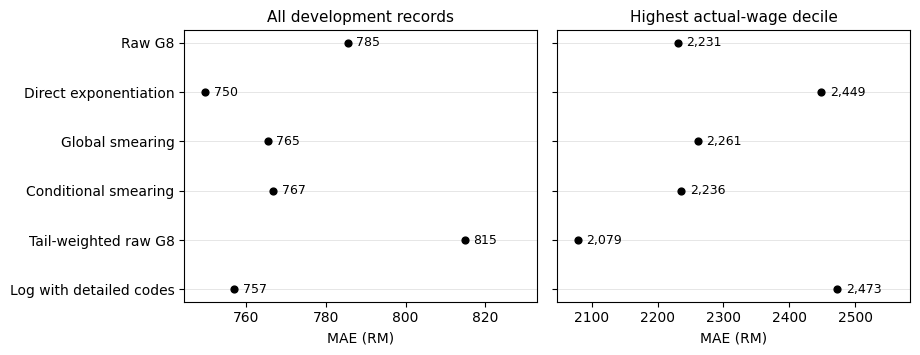

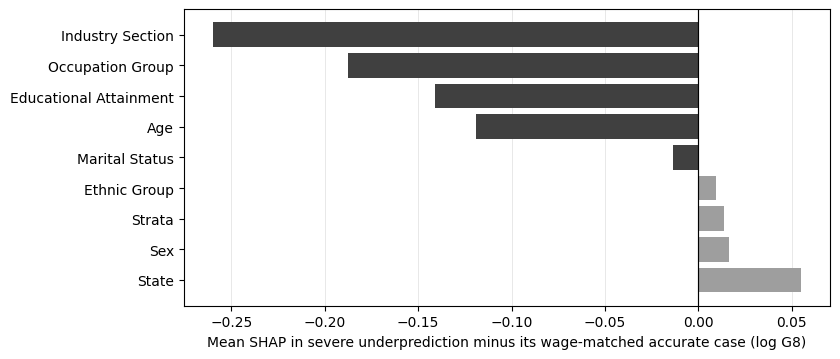

,Overall MAE (RM),Overall RMSE (RM),D10 MAE (RM),D10 mean error (RM),Nondominated on the two MAEs
Method,,,,,
A Original G8,785.45,1574.18,2230.79,-1853.62,True
B Direct exp,749.66,1579.51,2448.90,-2221.37,True
C Duan smearing,765.46,1561.62,2261.45,-1836.62,True
Conditional smearing,766.75,1560.96,2236.20,-1770.94,True
Tail-weighted raw RMSE,814.85,1588.48,2078.86,-1534.32,True
Log model with detailed codes,757.01,1587.61,2473.03,-2247.01,False


,Method,Mean actual G8 (RM),Mean prediction (RM),Rows,MAE (RM),RMSE (RM),Mean error (RM),Underpredicted (%)
0,A Original G8,14416.11,7010.70,289,7421.53,10084.43,-7405.41,99.65
1,B Direct exp,14416.11,6511.03,289,7922.35,10491.61,-7905.08,99.65
2,C Duan smearing,14416.11,6913.61,289,7528.09,10210.07,-7502.50,99.31
3,Conditional smearing,14416.11,6982.15,289,7461.27,10162.03,-7433.96,99.31
4,Tail-weighted raw RMSE,14416.11,7428.05,289,7001.44,9777.54,-6988.06,99.65
5,Log model with detailed codes,14416.11,6406.47,289,8009.63,10539.69,-8009.63,100.00


Section 13 passed. Verified tables and figures saved to /Users/liyiming/PycharmProjects/FYP_Salary_Prediction/results/week7/final_diagnostics/v1


In [19]:
# Week 7 - Section 13: Save development evidence and reporting figures
from matplotlib import pyplot as plt

assert len(w7_factorial_oof) == len(w7_remedy_oof) == len(w7_dup_eval) == 21_940
assert w7_factorial_oof.index.equals(w7_remedy_oof.index) and w7_remedy_oof.index.equals(w7_dup_eval.index)
assert all(len(frame) == 21_940 and frame.index.equals(w7_remedy_oof.index) for frame in w7_comparison_oof.values())
assert len(w7_duplicate_folds) == 10 and len(w7_shap_matches_by_fold) == 5
assert w7_duplicate_folds.loc[w7_duplicate_folds["Validation scheme"].eq("Exact-record grouped"), ["Outer matched validation rows", "Inner matched validation rows"]].eq(0).all().all()

w7_ten_k = w7_remedy_oof.loc[w7_remedy_oof["Actual G8"].ge(10_000)]
w7_ten_k_summary = pd.DataFrame([
    {"Method": name, "Mean actual G8 (RM)": w7_ten_k["Actual G8"].mean(),
     "Mean prediction (RM)": w7_ten_k[name].mean(), **w7_error_metrics(w7_ten_k["Actual G8"], w7_ten_k[name])}
    for name in w7_remedy_methods
])
w7_outcome = (
    w7_remedy_summary.loc[w7_remedy_summary["Group"].eq("All")].set_index("Method")[["MAE (RM)", "RMSE (RM)"]]
    .rename(columns={"MAE (RM)": "Overall MAE (RM)", "RMSE (RM)": "Overall RMSE (RM)"})
    .join(w7_remedy_summary.loc[w7_remedy_summary["Group"].eq("D10")].set_index("Method")[["MAE (RM)", "Mean error (RM)"]]
          .rename(columns={"MAE (RM)": "D10 MAE (RM)", "Mean error (RM)": "D10 mean error (RM)"}))
)
points = w7_outcome[["Overall MAE (RM)", "D10 MAE (RM)"]].to_numpy()
w7_outcome["Nondominated on the two MAEs"] = [
    not ((points <= point).all(axis=1) & (points < point).any(axis=1)).any() for point in points
]
w7_evidence_dir = W7_ROOT / "results" / "week7" / "final_diagnostics" / "v1"
w7_evidence_dir.mkdir(parents=True, exist_ok=True)
w7_evidence_tables = {
    "three_model_summary": w7_comparison_summary,
    "three_model_smearing_changes": w7_smearing_changes,
    "factorial_metrics": w7_factorial_summary,
    "factorial_contrasts": w7_factorial_effects,
    "mae_rmse_selection": w7_selection_summary,
    "decile_mae_contributions": w7_mae_deciles.reset_index(),
    "remedy_metrics": w7_remedy_summary,
    "remedy_fold_changes": w7_fold_tradeoffs,
    "conditional_smearing_factors": w7_conditional_factors.reset_index(),
    "rm10000_and_above": w7_ten_k_summary,
    "catboost_objective_tradeoffs": w7_outcome.reset_index(),
    "duplicate_fold_checks": w7_duplicate_folds,
    "duplicate_sensitivity": w7_duplicate_sensitivity,
    "d10_error_groups": w7_d10_error_groups,
    "d10_shap_cohorts": w7_shap_cohort_means,
    "d10_shap_matched": w7_shap_matched_summary,
    "d10_shap_pairs_by_fold": w7_shap_matches_by_fold,
    "predictor_profiles": w7_profile_diagnostic,
}
for name, frame in w7_evidence_tables.items():
    assert not frame.empty
    path = w7_evidence_dir / f"{name}.csv"
    tmp = path.with_suffix(".csv.tmp")
    frame.to_csv(tmp, index=False)
    tmp.replace(path)

fig, ax = plt.subplots(1, 2, figsize=(9.3, 3.65), sharey=True)
short = {
    "A Original G8": "Raw G8",
    "B Direct exp": "Direct exponentiation",
    "C Duan smearing": "Global smearing",
    "Conditional smearing": "Conditional smearing",
    "Tail-weighted raw RMSE": "Tail-weighted raw G8",
    "Log model with detailed codes": "Log with detailed codes",
}
labels = [short[name] for name in w7_outcome.index]
for axis, col, title in zip(ax, ["Overall MAE (RM)", "D10 MAE (RM)"], ["All development records", "Highest actual-wage decile"]):
    values = w7_outcome[col].to_numpy()
    axis.scatter(values, range(len(values)), color="black", s=24, zorder=3)
    for i, value in enumerate(values):
        axis.annotate(f"{value:,.0f}", (value, i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    axis.set_xlim(values.min() - 0.08 * np.ptp(values), values.max() + 0.28 * np.ptp(values))
    axis.set_title(title, fontsize=11)
    axis.set_xlabel("MAE (RM)")
    axis.grid(axis="y", color="0.90", linewidth=0.7)
ax[0].set_yticks(range(len(labels)), labels)
ax[0].invert_yaxis()
fig.tight_layout()
fig.savefig(w7_evidence_dir / "catboost_wage_accuracy.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

plot_shap = w7_shap_matched_summary.copy()
plot_shap["Feature"] = plot_shap["Feature"].str.replace("_", " ")
fig, axis = plt.subplots(figsize=(8.5, 3.7))
values = plot_shap["Mean SHAP difference"].to_numpy()
axis.barh(plot_shap["Feature"], values, color=np.where(values < 0, "0.25", "0.62"))
axis.axvline(0, color="black", linewidth=0.85)
axis.invert_yaxis()
axis.set_xlabel("Mean SHAP in severe underprediction minus its wage-matched accurate case (log G8)")
axis.grid(axis="x", color="0.9", linewidth=0.65)
axis.set_axisbelow(True)
fig.tight_layout()
fig.savefig(w7_evidence_dir / "matched_shap_contributions.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

w7_manifest = {
    "development_rows": len(w7_remedy_oof), "outer_folds": 5,
    "new_heldout_evaluation": False, "matched_shap_pairs": len(w7_d10_matched),
    "median_actual_wage_gap_pct": float(w7_d10_matched["Actual wage gap (%)"].median()),
    "max_log_shap_reconstruction_error": max(w7_d10_additivity.values()),
    "p99_actual_wage_rm": float(w7_p99), "exact_groups_multiple_records": int(row_groups.value_counts().gt(1).sum()),
    "extra_exact_records": int(len(row_groups) - row_groups.nunique()),
    "development_rows_moved_for_grouping": int(w7_moved_mask.sum()),
    "ordinary_outer_matches": int(w7_duplicate_folds.loc[w7_duplicate_folds["Validation scheme"].eq("Ordinary"), "Outer matched validation rows"].sum()),
    "ordinary_inner_matches": int(w7_duplicate_folds.loc[w7_duplicate_folds["Validation scheme"].eq("Ordinary"), "Inner matched validation rows"].sum()),
    "tables": list(w7_evidence_tables),
}
manifest_path = w7_evidence_dir / "completed.json"
manifest_tmp = manifest_path.with_suffix(".json.tmp")
manifest_tmp.write_text(json.dumps(w7_manifest, indent=2), encoding="utf-8")
manifest_tmp.replace(manifest_path)
display(w7_outcome.round(2))
display(w7_ten_k_summary.round(2))
print(f"Section 13 passed. Verified tables and figures saved to {w7_evidence_dir}")
